# Return convergence across training seeds — per snapshot

Overlays the learning curves of the **differently seeded training runs of a snapshot**, so the
seed spread behind the held-out results in
[`sps_eval_violins_seed_compare.ipynb`](sps_eval_violins_seed_compare.ipynb) can be read off
directly. `SNAPSHOTS` in the next cell lists the twelve GEN battery-capacity `_pp` snapshots:
SAC, PPO and DreamerV3, each trained on four configs — a single 17 kWh battery, a single 15 kWh
battery, N-way (cycling 10 / 13 / 17 / 20 / 25 kWh) and a capacity sampled per episode from
10-25 kWh that excludes the 12 / 16 / 22 kWh eval capacities — with five training seeds each.
Every snapshot is loaded, reduced and drawn **on its own**: two per-seed figures (training
return, in-training eval return) plus one across-seed mean/band figure, each with its own
seed→colour mapping, step-axis unit and x-grid. Only two things span snapshots: the per-series
y-cut `Y_LIMITS_DEFAULT`, so the per-seed figures compare at a glance, and the across-method
comparison at the end, which overlays the methods of one training config. Sibling of
[`../3_gen_bat_cap_v1/sps_train_return_convergence.ipynb`](../3_gen_bat_cap_v1/sps_train_return_convergence.ipynb),
which overlays several of the base snapshots (see below) in one figure instead — here every
curve of a per-seed figure comes from the same frozen code and trial config, and only
`training_params.common.seed` differs.

Line numbers cited in this notebook refer to the frozen `code/` of the listed snapshots —
identical across all twelve apart from their configs — not to the live repo, unless a path says
otherwise.

Seed fan-outs are produced with the snapshot submitter's `--common-seed`:

```bash
python -m tools.snapshot.submit_snapshot --snapshot snapshots/<existing>/ --kind train --common-seed 46
```

which copies the frozen `configs/` into the run dir, rewrites `training_params.common.seed`
there and names the run `train_<timestamp>_cseed{N}` (live repo:
`tools/snapshot/submit_snapshot.py:453-454`, `:478-485`). A snapshot's un-suffixed run is its
original training run with the seed its frozen trial YAML declares; a `_pp` snapshot holds none.

**Base snapshot, seed 42.** A `_pp` snapshot carries the same frozen `code/` and manifest as
an earlier snapshot — its **base snapshot**, the same path without `_pp` — but holds only the
`--common-seed` fan-out (seeds 46 / 71 / 97 / 141); the un-suffixed seed-42 run stays in the
base snapshot. For a `_pp` entry that base snapshot is read as well, restricted to its training
runs whose learner seed is `BASE_SNAPSHOT_SEED` (42), so that run joins the fan-out as one more
curve — the same rule `BASE_SNAPSHOT_EVAL_SEED` applies to the eval runs in
[`sps_eval_violins_seed_compare.ipynb`](sps_eval_violins_seed_compare.ipynb). Its seed is read
from its own `param_space.json` like every other run's, and the summary table marks it
`from = base`. For the twelve `_pp` snapshots the pairing was checked: base and `_pp` `code/`
differ only in `__pycache__` bytecode, and every fan-out run's trial YAML differs from the base
run's only by the `training_params.common.seed` line `--common-seed` adds.

**The seed of each run is read from that run's own `param_space.json`** (`"seed"` — the RLlib
algorithm config Ray was actually handed, written by `run_train_ray.py:166-169`), never from
the directory name: `common_model_setup` passes `training_config.seed` into
`config.debugging(...)` (`adv_building_gym/ray/training/common_model_config.py:225-228`), while
the tune run directory is named `<algorithm>_seed{trial.seed}_<timestamp>` after the
*top-level* seed (`run_train_ray.py:364`), which `--common-seed` leaves untouched. All 60 runs
keep the top-level `seed: 42`, so every one sits in a `<algorithm>_seed42_*` directory (e.g.
`sac_seed42_20261015_163454`) regardless of its actual learner seed.

**The algorithm of each snapshot is read from the filesystem too**, not from its name or from
the notebook input: `run_train_ray.py:365` stores a run under
`models/<trial_name>/ray/<algorithm>/…` (handed to tune's `RunConfig` at `:252-253`), so the
directory below `ray/` on the tune trial dir's path names the algorithm. It is reported per
snapshot and a snapshot whose runs disagree on it is an error.

For each run the main RLlib TBX log under `runs/train_*/models/**/events.out.tfevents.*` is
parsed (the `eval_trajectories/` sub-runs live under `ep_metrics/` and are not matched) and two
scalars are extracted:

| Series | Tag |
|---|---|
| training | `ray/tune/env_runners/episode_return_mean` |
| in-training eval | `ray/tune/evaluation/env_runners/episode_return_mean` |

> **Resumed runs:** a run restarted via `run_train_ray.py --restore` keeps writing into the
> *same* tune trial directory, so its curve is split over several event files with an overlap
> at the resume iteration. All event files of that directory are merged here (a step re-logged
> by a later file wins) — taking only the largest file would silently truncate such a run.
> None of the current runs was resumed: each has a single event file (`event_files` in the
> summary table).

> **Step axis:** the TBX step axis was switched from the tune iteration counter to
> `num_env_steps_sampled_lifetime` (commit `383a3e7`). Which one a snapshot used is detected
> per run by comparing its last logged step against `training_iteration` and
> `num_env_steps_sampled_lifetime` in the run's final tune result; `X_AXIS` then converts
> to episodes with that same result's `num_episodes_lifetime / training_iteration` ratio
> (the *measured* episodes-per-iteration, which for PPO exceeds `ppo.episodes_per_iteration`
> — 12.02 measured vs 10 configured — because RLlib overshoots the train batch to whole
> episodes across its EnvRunners). The unit is required to agree **within** a snapshot only.
> The listed snapshots predate `383a3e7` (it is not an ancestor of their manifest's `git_sha`)
> and all log on the iteration counter.

> **Unfinished runs:** `result_0.json` is written by `_dump_all_results`
> (`run_train_ray.py:311-334`) only once `tuner.fit()` has returned (`:412`, `:419`), so a run
> that hit its SLURM wall clock or is still training never gets one. Its TBX log and tune's own
> per-iteration JSON-lines stream `<trial_dir>/result.json` are both intact, so the step-axis
> counters are then read from the **last complete line of that stream** instead
> (`_final_metrics`). The scan runs backwards and skips a truncated final line, so a killed run
> still contributes its own real conversion factors; the median-of-other-runs fallback only
> fires when neither source exists, and it is taken over the runs of the *same* snapshot. All
> 60 runs of the current list finished and read `result_0.json` (`scales_from` in the summary
> table).

Parsing an event file is slow, so extracted curves are cached as small CSVs under
`.tb_return_cache/` next to this notebook; delete that folder to force a re-parse.

**Main input:** set `SNAPSHOTS` in the next cell — each entry with a `label` and the `config`
that groups it in the across-method comparison. The base-snapshot seed (`BASE_SNAPSHOT_SEED`),
figure sizes (`PER_SEED_FIGSIZE`, `BAND_FIGSIZE`), the per-seed y-cuts (`Y_LIMITS_DEFAULT`, with
per-label overrides in `Y_LIMITS`) and the episode budget (`MAX_EPISODES`, which drops every
point logged past it) live there as well. The last section tabulates every seed's return at
every `CHECKPOINT_EVERY`-th episode together with its across-seed mean / std / median, for both
series.

In [1]:
# --- Main input ---------------------------------------------------------------------
# The snapshots whose seeded training runs are plotted. Every entry is reduced on its own —
# its seed-colour assignment, step-axis unit and x-grid stay local — and drawn as two per-seed
# figures (training return, in-training eval return) plus one band figure. Only the per-series
# y-cut Y_LIMITS_DEFAULT and the across-method comparison (snapshots sharing a "config") span
# snapshots, so differently-algorithmed entries cannot interfere with each other otherwise.
# Keys per entry:
#   path            snapshot dir (absolute, or relative to the repo root)
#   label           optional short name for the headings, the table index and the output
#                   filenames; defaults to the snapshot directory name
#   config          optional training-config name; the across-method comparison draws one
#                   figure per config, with the snapshots sharing it as its methods. It is
#                   used in the output filename. Entries without it stay out of that comparison.
#   run_glob        optional per-snapshot override of RUN_GLOB
#   skip_first_run  optional per-snapshot override of SKIP_FIRST_RUN
#   max_episodes    optional per-snapshot override of MAX_EPISODES
#   base_seed       optional per-snapshot override of BASE_SNAPSHOT_SEED
#
# The algorithm of each snapshot is not configured here — it is read back from the path Ray
# wrote its checkpoints to (models/<trial>/ray/<algo>, run_train_ray.py:365) and reported in
# the summary table, so a mixed list stays self-documenting.
SNAPSHOTS = [
    {"path": "snapshots/20260714_161830_gen_battery_lin_so_only_17kW_sac_cp_pp", "label": "SAC_17kWh", "config": "17kWh"},
    {"path": "snapshots/20260714_235241_gen_battery_lin_so_only_15kW_sac_cp_pp", "label": "SAC_15kWh", "config": "15kWh"},
    {"path": "snapshots/20260714_162614_gen_battery_lin_so_all_sac_v2_pp", "label": "SAC_N-way", "config": "N-way"},
    {"path": "snapshots/20260714_165943_gen_battery_lin_capacity_sampled_sac_pp", "label": "SAC_distr", "config": "distr"},
    {"path": "snapshots/20260714_235444_gen_battery_lin_so_only_17kW_ppo_cp_pp", "label": "PPO_17kWh", "config": "17kWh"},
    {"path": "snapshots/20260714_235342_gen_battery_lin_so_only_15kW_ppo_cp_pp", "label": "PPO_15kWh", "config": "15kWh"},
    {"path": "snapshots/20260714_235542_gen_battery_lin_so_all_ppo_v2_cp_pp", "label": "PPO_N-way", "config": "N-way"},
    {"path": "snapshots/20260714_235647_gen_battery_lin_capacity_sampled_ppo_cp_pp", "label": "PPO_distr", "config": "distr"},
    {"path": "snapshots/20260714_225444_gen_battery_lin_so_only_17kW_dreamer_pp", "label": "DreamerV3_17kWh", "config": "17kWh"},
    {"path": "snapshots/20260714_225342_gen_battery_lin_so_only_15kW_dreamer_pp", "label": "DreamerV3_15kWh", "config": "15kWh"},
    {"path": "snapshots/20260714_225542_gen_battery_lin_so_all_dreamer_v2_pp", "label": "DreamerV3_N-way", "config": "N-way"},
    {"path": "snapshots/20260714_225647_gen_battery_lin_capacity_sampled_dreamer_pp", "label": "DreamerV3_distr", "config": "distr"},
]

# Restricts the picked-up run directories; "train_*" takes the original run plus every
# --common-seed fan-out. Set e.g. "train_*_cseed*" to drop the original. A `_pp` snapshot
# holds only the fan-out; its original seed-42 run comes in through BASE_SNAPSHOT_SEED. A
# snapshot entry can override it with its own "run_glob" key.
RUN_GLOB = "train_*"

# Drops the alphabetically first matched run directory (the snapshot's own training run,
# which sorts before its later --common-seed fan-outs). Kept as an explicit switch so a
# dropped seed is always a deliberate choice; RUN_GLOB can exclude the original as well. In a
# `_pp` snapshot, which holds only fan-outs, it drops the earliest fan-out instead — the base
# run is excluded with BASE_SNAPSHOT_SEED = None (or the entry's "base_seed": None).
# Per-snapshot override: the entry's "skip_first_run" key.
SKIP_FIRST_RUN = False

# A snapshot whose path ends in `_pp` also reads its base snapshot (same path without `_pp`),
# but only the base training runs whose learner seed (param_space.json) is this one; they join
# that snapshot's figures and tables as one more seed. RUN_GLOB / SKIP_FIRST_RUN select among
# the listed snapshot's runs only — the base run is picked by its seed alone. Same rule as
# BASE_SNAPSHOT_EVAL_SEED in sps_eval_violins_seed_compare.ipynb. None reads the listed
# snapshots only. Per-snapshot override: the entry's "base_seed" key.
BASE_SNAPSHOT_SEED: int | None = 42

# The two RLlib return scalars, plotted as the training / eval series. Both are produced for
# every snapshot in SNAPSHOTS.
TRAIN_METRIC = "ray/tune/env_runners/episode_return_mean"
EVAL_METRIC = "ray/tune/evaluation/env_runners/episode_return_mean"

# TensorBoard-style EWMA weight in [0, 1): 0 = raw, higher = smoother. The raw curve is drawn
# faint behind the smoothed one when SHOW_RAW is True.
SMOOTHING = 0.99
SHOW_RAW = True

# The training and eval per-seed figures are separate; SHARE_Y puts the two figures OF ONE
# SNAPSHOT on one common y-range so they stay comparable side by side in the thesis. The
# range is always computed per snapshot — never across snapshots, whose return levels differ.
# With both bounds of Y_LIMITS_DEFAULT set, that cut replaces this range in the per-seed
# figures; SHARE_Y only shows through a None bound.
SHARE_Y = True

# Y-axis cut of the per-seed figures per series ("train" / "eval"), as a (y_min, y_max) pair.
# Y_LIMITS_DEFAULT applies to every snapshot, so all per-seed figures of one series share one
# range and compare at a glance across methods and training configs; Y_LIMITS overrides it per
# snapshot label and series. Either bound may be None to leave that side at the SHARE_Y /
# automatic limit, so an override of (None, None) drops the cut for that figure. Curves are
# clipped, not dropped — the data is untouched.
# The defaults cut the first-episodes dip (smoothed DreamerV3 training returns start below 0)
# and keep the top of every smoothed curve: the highest smoothed values are 15.4 (training)
# and 16.5 (eval), both SAC. Only the highest raw spikes are clipped (SAC, up to 23.7 / 18.5).
Y_LIMITS_DEFAULT: dict[str, tuple[float | None, float | None]] = {
    "train": (2.0, 20.0),
    "eval": (4.0, 18.0),
}
Y_LIMITS: dict[str, dict[str, tuple[float | None, float | None]]] = {
    # e.g. "DreamerV3_15kWh": {"train": (-2.0, 16.0)},
}

# Y-axis tick spacing in return units: ticks land on every multiple of Y_TICK_STEP, so 0.5
# guarantees a labelled tick at least every half return unit. None restores matplotlib's
# automatic locator. Y_MINOR_TICK_STEP adds unlabelled minor ticks plus a lighter gridline
# in between, which is how a fine ruling stays readable without stacking dozens of labels:
# e.g. Y_TICK_STEP = 2.0 with Y_MINOR_TICK_STEP = 0.5 rules every 0.5 units but labels
# every 2. A step finer than the tick labels can fit is drawn anyway — matplotlib does not
# thin them out, so check the figure when the y-range is wide.
# Link: https://matplotlib.org/stable/api/ticker_api.html#matplotlib.ticker.MultipleLocator
Y_TICK_STEP = 2.0
Y_MINOR_TICK_STEP = 0.5

# Figure sizes in inches, (width, height).
PER_SEED_FIGSIZE = (7.0, 3)  # the two per-seed figures of each snapshot
BAND_FIGSIZE = (7.0, 3)      # the across-seed mean + spread figure of each snapshot

# Text size. Matplotlib sizes fonts in POINTS, independently of *_FIGSIZE, so shrinking a
# figure leaves axis labels, ticks and legend at their absolute size — which is why they
# look large on a smaller figure. These two knobs shrink the text itself: PLOT_CONTEXT picks
# seaborn's base sizes ("paper" = 0.8x "notebook", "talk" = 1.3x, "poster" = 1.6x) and
# FONT_SCALE multiplies every text element on top of that. The plotting cell prints the
# resulting point sizes.
# Link: https://seaborn.pydata.org/generated/seaborn.set_context.html
PLOT_CONTEXT = "notebook"
FONT_SCALE = 0.7

# Legend text in points, overriding the scaled context for the legend alone (it carries one
# entry per seed, so it is usually the first thing worth shrinking). None keeps the context.
LEGEND_FONTSIZE = None

# x-axis unit: "episodes", "iterations" (the raw TBX step of these snapshots) or
# "env_steps" (millions). The conversion factors are read per run from its final tune result
# (result_0.json, else the last line of tune's per-iteration result.json stream).
X_AXIS = "episodes"
EPISODE_LENGTH = 288  # env_meta.EPISODE_LENGTH of the trial; only used for env-step-indexed logs

# Upper end of the x-axis, in the unit X_AXIS selects (episodes / iterations / millions of
# env steps). Set it to give every figure the same horizontal extent — e.g. 7000 episodes
# puts a snapshot whose runs stopped at 3300 episodes on the same axis as one that ran the
# full budget, so the two are visually comparable. None keeps matplotlib's automatic right
# limit, i.e. each figure ends at its own longest run. It only changes the view: curves are
# neither cut from the data nor extrapolated, and the aggregate band still stops where the
# shortest run of its snapshot ends.
X_MAX = 7000

# Episode budget: every point logged past this many training episodes is DROPPED from both
# series at load time, before smoothing, so the per-seed figures, the summary table, the
# bands and the checkpoint tables all end there. Unlike X_MAX (a view limit) this changes
# the data. Measured on the plotted episode axis (TBX step x the run's episodes_per_step).
# The PPO fan-out's last iteration lands at ~7008 episodes, past the 7000-episode budget;
# 7000 cuts that overshoot off. None keeps every point. Per-snapshot override: the entry's
# "max_episodes" key.
MAX_EPISODES = 7000

# Spread drawn around the across-seed mean in the aggregate figure:
# "std" (± 1 standard deviation), "minmax" or "iqr" (25-75 %).
BAND = "std"

# Filename prefix of the saved figures; the snapshot label is prefixed per figure, so the
# output of one notebook run stays attributable to its snapshot.
OUT_PREFIX = "seeds_return"

In [2]:
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
import pandas as pd
import seaborn as sns
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util


# Walk upwards from the cwd until the directory containing snapshots/ is found, so the
# notebook runs both from thesis_eval/ and from the repo root.
def _find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "snapshots").is_dir():
            return candidate
    raise FileNotFoundError("No 'snapshots/' directory found upwards of the cwd — run inside the repo.")


REPO_ROOT = _find_repo_root()

# VS Code exposes the notebook path; a plain Jupyter kernel starts in the notebook's directory.
NB_DIR = Path(globals()["__vsc_ipynb_file__"]).parent if "__vsc_ipynb_file__" in globals() else Path.cwd()
CACHE_DIR = NB_DIR / ".tb_return_cache"


# One SNAPSHOTS entry's path as an existing directory (absolute paths pass through).
def _resolve_snapshot_dir(path: str) -> Path:
    snapshot_dir = Path(path)
    snapshot_dir = snapshot_dir if snapshot_dir.is_absolute() else REPO_ROOT / snapshot_dir
    if not snapshot_dir.is_dir():
        raise FileNotFoundError(f"Snapshot directory not found: {snapshot_dir}")
    return snapshot_dir


# The tune trial directory of a run's main RLlib TBX log, plus its event files oldest first.
# A resumed run (run_train_ray.py --restore) keeps writing into the same tune trial
# directory, so its curve is spread over several event files — all of them belong to the
# run. The trial directory with the largest total event bytes wins if a run somehow holds
# more than one. That directory also holds tune's own per-iteration `result.json` stream,
# which the step-axis fallback below reads.
def _training_trial_dir(run_dir: Path) -> tuple[Path, list[Path]]:
    candidates = list(run_dir.glob("models/**/events.out.tfevents.*"))
    if not candidates:
        raise FileNotFoundError(f"No training TBX event file under {run_dir / 'models'}")
    by_trial_dir: dict[Path, list[Path]] = {}
    for path in candidates:
        by_trial_dir.setdefault(path.parent, []).append(path)
    trial_dir = max(by_trial_dir, key=lambda directory: sum(p.stat().st_size for p in by_trial_dir[directory]))
    return trial_dir, sorted(by_trial_dir[trial_dir], key=lambda path: path.stat().st_mtime)


def _training_event_files(run_dir: Path) -> list[Path]:
    return _training_trial_dir(run_dir)[1]


# The algorithm a run was trained with, read back from the path Ray stored it under:
# run_train_ray.py:365 builds storage_path as `models/<trial_name>/ray/<algorithm>` and
# tune's RunConfig (run_train_ray.py:252-253) puts the run (and below it the tune trial dir) inside it, so the
# directory whose own parent is "ray" carries the algorithm name. Reported per snapshot so a
# mixed SNAPSHOTS list shows which algorithm each figure belongs to.
def _run_algorithm(run_dir: Path) -> str:
    trial_dir = _training_trial_dir(run_dir)[0]
    for parent in trial_dir.parents:
        if parent.parent.name == "ray":
            return parent.name
    return "unknown"


# Extracts the requested scalar tags from one run's event files into a long frame
# (tag, step, value), caching the result as a CSV keyed by every input file's
# path + size + mtime (so a resumed / extended run re-parses).
def _extract_curves(event_files: list[Path], tags: tuple[str, ...]) -> pd.DataFrame:
    fingerprint = "|".join(
        f"{path}:{path.stat().st_size}:{int(path.stat().st_mtime)}" for path in event_files
    ) + "|" + ",".join(sorted(tags))
    cache_path = CACHE_DIR / f"{hashlib.md5(fingerprint.encode()).hexdigest()}.csv"
    if cache_path.exists():
        return pd.read_csv(cache_path)

    rows = []
    for file_order, event_file in enumerate(event_files):
        for event in EventFileLoader(str(event_file)).Load():
            for value in event.summary.value:
                if value.tag not in tags:
                    continue
                # RLlib writes scalars in the tensor field; legacy simple_value is the fallback.
                scalar = float(tensor_util.make_ndarray(value.tensor)) if value.HasField("tensor") else value.simple_value
                rows.append({"tag": value.tag, "step": event.step, "value": scalar, "file_order": file_order})
    if not rows:
        raise ValueError(f"None of {tags} found in {[str(p) for p in event_files]}")

    curves = (
        pd.DataFrame(rows)
        .sort_values(["tag", "file_order", "step"])
        # Resume overlap: the same step logged again by a later event file wins.
        .drop_duplicates(["tag", "step"], keep="last")
        .sort_values(["tag", "step"])
        .reset_index(drop=True)
    )
    CACHE_DIR.mkdir(exist_ok=True)
    curves.to_csv(cache_path, index=False)
    return curves


_CSEED_SUFFIX_REGEX = re.compile(r"_cseed(-?\d+)$")


# The learner seed Ray actually ran with: param_space.json is the algorithm config dump
# (run_train_ray.py:166-169) whose "seed" is training_params.common.seed. The _cseed{N} run-id
# suffix is only a fallback for runs whose param_space.json is missing.
def _run_seed(run_dir: Path) -> tuple[int | None, str]:
    param_space_path = run_dir / "param_space.json"
    if param_space_path.is_file():
        try:
            seed = json.loads(param_space_path.read_text()).get("seed")
        except (json.JSONDecodeError, OSError):
            seed = None
        if seed is not None:
            return int(seed), "param_space.json"
    match = _CSEED_SUFFIX_REGEX.search(run_dir.name)
    if match:
        return int(match.group(1)), "run-id suffix"
    return None, "unresolved"


# The three counters the x-axis conversion needs, pulled out of one tune result dict.
# Returns None when the dict does not carry all of them (early iterations, partially
# written line).
def _scale_counters(metrics: dict) -> tuple[float, float, float] | None:
    try:
        iterations = float(metrics["training_iteration"])
        env_steps = float(metrics["num_env_steps_sampled_lifetime"])
        episodes = float(metrics["env_runners"]["num_episodes_lifetime"])
    except (KeyError, TypeError, ValueError):
        return None
    if iterations <= 0.0:
        return None
    return iterations, env_steps, episodes


# The run's final tune result. `result_0.json` is written by `_dump_all_results` only after
# `tuner.fit()` returns (run_train_ray.py:311-334, called at :419), so a run that was killed or is still
# training has none. Tune's own JSON-lines stream in the trial directory
# (`<trial>/result.json`, one reported result per line, same schema) survives that, so the
# last complete line of it is the fallback — the counters there are the real ones of the
# unfinished run, not borrowed from a sibling.
def _final_metrics(run_dir: Path) -> tuple[dict, str] | None:
    result_path = run_dir / "result_0.json"
    if result_path.is_file():
        try:
            metrics = json.loads(result_path.read_text())["metrics"]
        except (json.JSONDecodeError, OSError, KeyError):
            metrics = None
        if metrics is not None and _scale_counters(metrics) is not None:
            return metrics, "result_0.json"

    trial_result_path = _training_trial_dir(run_dir)[0] / "result.json"
    if not trial_result_path.is_file():
        return None
    try:
        lines = trial_result_path.read_text().splitlines()
    except OSError:
        return None
    # Backwards: a killed run can leave a truncated final line, and the very first results
    # of a run may predate some counters.
    for line in reversed(lines):
        if not line.strip():
            continue
        try:
            metrics = json.loads(line)
        except json.JSONDecodeError:
            continue
        if _scale_counters(metrics) is not None:
            return metrics, "trial result.json"
    return None


# Step-axis unit and x-axis conversion factors, taken from the run's final tune result.
# Returns None only when neither result source exists — the caller then falls back to the
# median of the runs that do have one.
def _run_step_scales(run_dir: Path, last_step: float) -> dict | None:
    resolved = _final_metrics(run_dir)
    if resolved is None:
        return None
    metrics, source = resolved
    iterations, env_steps, episodes = _scale_counters(metrics)
    # Iteration-indexed vs env-step-indexed logs differ by ~3 orders of magnitude, so the
    # last logged step identifies the unit unambiguously.
    if abs(last_step - iterations) <= abs(last_step - env_steps):
        return {
            "step_unit": "iteration",
            "episodes_per_step": episodes / iterations,
            "env_steps_per_step": env_steps / iterations,
            "source": source,
        }
    return {
        "step_unit": "env_step",
        "episodes_per_step": 1.0 / EPISODE_LENGTH,
        "env_steps_per_step": 1.0,
        "source": source,
    }


# TensorBoard's debiased exponential moving average (the "smoothing" slider).
def _tb_smooth(values, weight: float) -> np.ndarray:
    if weight <= 0.0:
        return np.asarray(values, dtype=float)
    smoothed, last, debias_weight = [], 0.0, 0.0
    for value in values:
        last = last * weight + (1.0 - weight) * float(value)
        debias_weight = debias_weight * weight + (1.0 - weight)
        smoothed.append(last / debias_weight)
    return np.asarray(smoothed, dtype=float)


print(f"Repo root: {REPO_ROOT}\nCache dir: {CACHE_DIR}")
for entry in SNAPSHOTS:
    resolved_dir = _resolve_snapshot_dir(entry["path"])
    print(f"Snapshot : {entry.get('label', resolved_dir.name):<12} {resolved_dir}")

Repo root: /hkfs/home/haicore/iai/dj0397/AdvBuildingGym
Cache dir: /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/.tb_return_cache
Snapshot : SAC_17kWh    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_161830_gen_battery_lin_so_only_17kW_sac_cp_pp
Snapshot : SAC_15kWh    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_235241_gen_battery_lin_so_only_15kW_sac_cp_pp
Snapshot : SAC_N-way    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_162614_gen_battery_lin_so_all_sac_v2_pp
Snapshot : SAC_distr    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_165943_gen_battery_lin_capacity_sampled_sac_pp
Snapshot : PPO_17kWh    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_235444_gen_battery_lin_so_only_17kW_ppo_cp_pp
Snapshot : PPO_15kWh    /hkfs/home/haicore/iai/dj0397/AdvBuildingGym/snapshots/20260714_235342_gen_battery_lin_so_only_15kW_ppo_cp_pp
Snapshot : PPO_N-way    /hkfs/home/haicore/iai/dj0397/AdvBuild

## Output naming

Everything saved here lands next to the notebook as
`<label>_<prefix>_<date>_<time>_out_<i>.<file format>`: one timestamp per notebook run,
`out_index` counting up per saved artefact, so no run overwrites an earlier one. `<label>` is
the snapshot label for the three figures of each snapshot, `methods_<config>` for the
across-method comparison figures (one per training config and series) and
`checkpoints_<series>` for the two checkpoint-table CSVs, so every file stays attributable when
one run covers several snapshots.

In [3]:
from datetime import datetime

OUT_DIR = NB_DIR
OUT_RUN_STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
out_index = 0  # incremented once per saved artefact; reset by re-running this cell


def next_out_path(label: str, file_format: str) -> Path:
    """Next '<label>_<prefix>_<date>_<time>_out_<i>.<file_format>' path in this notebook's directory.

    `label` is the snapshot's label, so a figure stays attributable to the snapshot it came
    from even when one notebook run covers several snapshots.
    """
    global out_index
    out_index += 1
    stem = f"{label}_{OUT_PREFIX}_{OUT_RUN_STAMP}_out_{out_index}"
    return OUT_DIR / f"{stem}.{file_format}"

## Load the per-seed curves

One record per `runs/train_*` directory of every listed snapshot — plus, for a `_pp` snapshot,
its base snapshot's run on `BASE_SNAPSHOT_SEED` (`from = base` in the table): its seed, the number of
merged event files, the training and eval curves, and the step-axis scales. The table below is
indexed by `(snapshot, seed)` — each snapshot's block lists how far its seeds ran and where
their returns ended up. `final_*` is the last **smoothed** value (`SMOOTHING`), which is what
the plots below show, while `max_eval` is the raw best in-training eval return.

Points past the episode budget (`MAX_EPISODES`, or the entry's `max_episodes`) are dropped
here, right after the x-axis scales are resolved and before smoothing, so every table and
figure below — `last_step`, `episodes` and the `final_*` columns included — ends at the budget.
The printed line per snapshot says how many points per series the cut removed.

The `scales_from` column names where each run's x-axis conversion came from:
`result_0.json` for a run whose tuner finished, `trial result.json` for one that was killed or
is still training (tune's per-iteration stream in the trial directory — same counters, so the
x-axis is exact either way). Only a run with neither source falls back to the median scales of
the other runs **of its own snapshot**, with a note printed; its curve length is real and only
the episode/env-step conversion of its x-axis is borrowed. Every run of the current list reads
`result_0.json`.

The seed-uniqueness, step-unit and algorithm checks all run per snapshot: two snapshots may
reuse the same seed numbers, differ in TBX step unit and of course differ in algorithm, while
a *single* snapshot with duplicated seeds, mixed step units or mixed algorithms is still an
error. A base-snapshot run counts as one of its `_pp` snapshot's runs for all three checks, so a
fan-out that already holds a seed-42 run fails the seed check instead of drawing two seed-42
curves.

In [4]:
# Everything below is computed per snapshot and stored in that snapshot's own dict — its
# records, its step unit, its seed→colour mapping, its summary table. Nothing is shared
# across snapshots, so a SAC and a DreamerV3 entry in SNAPSHOTS cannot affect each other's
# figures (different return levels, step units and seed sets all stay local).
# Training runs of a `_pp` snapshot's base snapshot (same path without `_pp`) whose learner
# seed is `base_seed` — read via _run_seed, never from the directory name. Empty for a
# non-`_pp` snapshot or base_seed None; a missing base snapshot or one without a run on that
# seed is reported. Mirrors the BASE_SNAPSHOT_EVAL_SEED lookup of sps_eval_violins_seed_compare.ipynb.
def _base_run_dirs(snapshot_dir: Path, base_seed: int | None, label: str) -> list[Path]:
    base_dir = snapshot_dir.with_name(snapshot_dir.name.removesuffix("_pp"))
    if base_seed is None or base_dir == snapshot_dir:
        return []
    if not base_dir.is_dir():
        print(f"note: [{label}] base snapshot {base_dir.name} not found — only {snapshot_dir.name} is read")
        return []
    base_runs = [
        run_dir for run_dir in sorted((base_dir / "runs").glob("train_*"))
        if run_dir.is_dir() and _run_seed(run_dir)[0] == base_seed
    ]
    if not base_runs:
        print(f"WARNING: [{label}] base snapshot {base_dir.name} has no training run on seed {base_seed}")
    return base_runs


def _load_snapshot(entry: dict) -> dict:
    snapshot_dir = _resolve_snapshot_dir(entry["path"])
    label = entry.get("label", snapshot_dir.name)
    run_glob = entry.get("run_glob", RUN_GLOB)
    skip_first_run = entry.get("skip_first_run", SKIP_FIRST_RUN)

    run_dirs = sorted((snapshot_dir / "runs").glob(run_glob))
    if not run_dirs:
        raise FileNotFoundError(f"[{label}] No run directories matching '{run_glob}' under {snapshot_dir / 'runs'}")

    run_sources = [(run_dir, "listed") for run_dir in (run_dirs[1:] if skip_first_run else run_dirs)]
    base_seed = entry.get("base_seed", BASE_SNAPSHOT_SEED)
    run_sources += [(run_dir, "base") for run_dir in _base_run_dirs(snapshot_dir, base_seed, label)]

    records = []
    for run_dir, run_source in run_sources:
        if not run_dir.is_dir():
            continue
        seed, seed_source = _run_seed(run_dir)
        if seed is None:
            print(f"WARNING: [{label}] no seed resolvable for {run_dir.name} — run skipped")
            continue
        event_files = _training_event_files(run_dir)
        curves = _extract_curves(event_files, (TRAIN_METRIC, EVAL_METRIC))
        series = {
            name: curves.loc[curves["tag"] == tag, ["step", "value"]].reset_index(drop=True)
            for name, tag in (("train", TRAIN_METRIC), ("eval", EVAL_METRIC))
        }
        missing = [name for name, frame in series.items() if frame.empty]
        if missing:
            raise ValueError(f"[{label}] {run_dir.name}: no points for {missing} — check the metric tags")
        records.append({
            "run": run_dir.name,
            "from": run_source,
            "seed": seed,
            "seed_source": seed_source,
            "algorithm": _run_algorithm(run_dir),
            "event_files": len(event_files),
            "curves": series,
            "scales": _run_step_scales(run_dir, float(series["train"]["step"].iloc[-1])),
        })

    if not records:
        raise FileNotFoundError(f"[{label}] No usable runs matching '{run_glob}' under {snapshot_dir / 'runs'}")

    seeds = [record["seed"] for record in records]
    if len(seeds) != len(set(seeds)):
        raise ValueError(f"[{label}] Two runs report the same seed ({seeds}) — the curves would be indistinguishable")
    records.sort(key=lambda record: record["seed"])

    # A snapshot is one frozen trial config, so its runs must all be the same algorithm;
    # a mixed one would put incomparable curves on a single axes.
    algorithms = {record["algorithm"] for record in records}
    if len(algorithms) > 1:
        raise ValueError(f"[{label}] Runs disagree on the algorithm ({sorted(algorithms)}) — split them into separate snapshots")
    algorithm = algorithms.pop()

    # Runs without a final tune result inherit the median scales of the runs that have one.
    resolved_scales = [record["scales"] for record in records if record["scales"] is not None]
    if not resolved_scales:
        raise FileNotFoundError(
            f"[{label}] No run exposes a final tune result (neither result_0.json nor <trial>/result.json) "
            "— the step-axis unit cannot be resolved"
        )
    step_units = {scale["step_unit"] for scale in resolved_scales}
    if len(step_units) > 1:
        raise ValueError(f"[{label}] Runs disagree on the TBX step unit ({step_units}) — plot them separately")
    step_unit = step_units.pop()
    median_scales = {
        "step_unit": step_unit,
        "episodes_per_step": float(np.median([scale["episodes_per_step"] for scale in resolved_scales])),
        "env_steps_per_step": float(np.median([scale["env_steps_per_step"] for scale in resolved_scales])),
        "source": "median of other runs",
    }
    for record in records:
        if record["scales"] is None:
            print(f"note: [{label}] {record['run']} has neither result_0.json nor a tune result.json — "
                  "x-axis scales taken from the other runs")
            record["scales"] = median_scales

    # Episode budget: drop every point past max_episodes on the plotted episode axis. Done
    # before smoothing so no dropped point feeds the EWMA or any table below. The small
    # tolerance keeps a point that lands exactly on the budget despite float rounding.
    max_episodes = entry.get("max_episodes", MAX_EPISODES)
    dropped_points = {"train": 0, "eval": 0}
    if max_episodes is not None:
        for record in records:
            for name, curve in record["curves"].items():
                within_budget = curve["step"] * record["scales"]["episodes_per_step"] <= max_episodes + 1e-6
                if not within_budget.any():
                    raise ValueError(f"[{label}] {record['run']}: no {name} point within MAX_EPISODES={max_episodes}")
                dropped_points[name] += int((~within_budget).sum())
                record["curves"][name] = curve[within_budget].reset_index(drop=True)

    for record in records:
        for name in ("train", "eval"):
            record[f"smoothed_{name}"] = _tb_smooth(record["curves"][name]["value"].to_numpy(), SMOOTHING)

    # One colour per seed, assigned within this snapshot only.
    seed_palette = dict(zip([record["seed"] for record in records], sns.color_palette("colorblind", len(records))))

    summary = pd.DataFrame([{
        "seed": record["seed"],
        "run": record["run"],
        "from": record["from"],
        "seed_from": record["seed_source"],
        "event_files": record["event_files"],
        "scales_from": record["scales"]["source"],
        "last_step": int(record["curves"]["train"]["step"].iloc[-1]),
        "episodes": int(record["curves"]["train"]["step"].iloc[-1] * record["scales"]["episodes_per_step"]),
        "train_points": len(record["curves"]["train"]),
        "eval_points": len(record["curves"]["eval"]),
        "final_train": round(float(record["smoothed_train"][-1]), 3),
        "final_eval": round(float(record["smoothed_eval"][-1]), 3),
        "max_eval": round(float(record["curves"]["eval"]["value"].max()), 3),
    } for record in records]).set_index("seed")

    return {
        "label": label,
        "config": entry.get("config"),
        "dir": snapshot_dir,
        "algorithm": algorithm,
        "records": records,
        "step_unit": step_unit,
        "max_episodes": max_episodes,
        "dropped_points": dropped_points,
        "seed_palette": seed_palette,
        "summary": summary,
    }


labels = [entry.get("label", _resolve_snapshot_dir(entry["path"]).name) for entry in SNAPSHOTS]
if len(labels) != len(set(labels)):
    raise ValueError(f"Snapshot labels must be unique (they key Y_LIMITS and the output filenames): {labels}")

snapshots = [_load_snapshot(entry) for entry in SNAPSHOTS]

# The train/eval pair colours of the aggregate figure — the per-seed figures use the
# snapshot's own seed palette instead.
TRAIN_COLOR = "#0d54c4"  # strong blue
EVAL_COLOR = "#e2660a"   # strong orange

for snapshot in snapshots:
    base_seeds = [record["seed"] for record in snapshot["records"] if record["from"] == "base"]
    print(f"{snapshot['label']}: algorithm {snapshot['algorithm']}, {len(snapshot['records'])} seeds "
          f"(from the base snapshot: {base_seeds or 'none'}), "
          f"step unit {snapshot['step_unit']} ({X_AXIS} on the x-axis), cut at {snapshot['max_episodes']} episodes "
          f"(dropped over all seeds: {snapshot['dropped_points']['train']} train / "
          f"{snapshot['dropped_points']['eval']} eval points)")

summary = pd.concat(
    {snapshot["label"]: snapshot["summary"] for snapshot in snapshots}, names=["snapshot", "seed"]
)
summary

SAC_17kWh: algorithm sac, 5 seeds (from the base snapshot: [42]), step unit iteration (episodes on the x-axis), cut at 7000 episodes (dropped over all seeds: 0 train / 0 eval points)
SAC_15kWh: algorithm sac, 5 seeds (from the base snapshot: [42]), step unit iteration (episodes on the x-axis), cut at 7000 episodes (dropped over all seeds: 0 train / 0 eval points)
SAC_N-way: algorithm sac, 5 seeds (from the base snapshot: [42]), step unit iteration (episodes on the x-axis), cut at 7000 episodes (dropped over all seeds: 0 train / 0 eval points)
SAC_distr: algorithm sac, 5 seeds (from the base snapshot: [42]), step unit iteration (episodes on the x-axis), cut at 7000 episodes (dropped over all seeds: 0 train / 0 eval points)
PPO_17kWh: algorithm ppo, 5 seeds (from the base snapshot: [42]), step unit iteration (episodes on the x-axis), cut at 7000 episodes (dropped over all seeds: 5 train / 5 eval points)
PPO_15kWh: algorithm ppo, 5 seeds (from the base snapshot: [42]), step unit iteration

run    from  \
snapshot        seed                                           
SAC_17kWh       42             train_20260916_120814    base   
                46     train_20261015_163235_cseed46  listed   
                71     train_20261015_163236_cseed71  listed   
                97     train_20261015_163237_cseed97  listed   
                141   train_20261015_163238_cseed141  listed   
SAC_15kWh       42             train_20260912_121010    base   
                46     train_20261015_163649_cseed46  listed   
                71     train_20261015_163650_cseed71  listed   
                97     train_20261015_163652_cseed97  listed   
                141   train_20261015_163653_cseed141  listed   
SAC_N-way       42             train_20260803_005956    base   
                46     train_20261015_234752_cseed46  listed   
                71     train_20261015_234754_cseed71  listed   
                97     train_20261015_234755_cseed97  listed   
                141   train_20261015_234756_cseed141  listed   
SAC_distr       42             train_20260714_165947    base   
                46     train_20261017_125416_cseed46  listed   
                71     train_20261017_125418_cseed71  listed   
                97     train_20261017_125419_cseed97  listed   
                141   train_20261017_125420_cseed141  listed   
PPO_17kWh       42             train_20260912_111730    base   
                46     train_20261017_125520_cseed46  listed   
                71     train_20261017_125522_cseed71  listed   
                97     train_20261017_125523_cseed97  listed   
                141   train_20261017_125524_cseed141  listed   
PPO_15kWh       42             train_20260912_111731    base   
                46     train_20261017_125511_cseed46  listed   
                71     train_20261017_125512_cseed71  listed   
                97     train_20261017_125513_cseed97  listed   
                141   train_20261017_125514_cseed141  listed   
PPO_N-way       42             train_20260912_111728    base   
                46     train_20261020_144404_cseed46  listed   
                71     train_20261020_144421_cseed71  listed   
                97     train_20261020_144422_cseed97  listed   
                141   train_20261020_144423_cseed141  listed   
PPO_distr       42             train_20260912_111727    base   
                46     train_20261020_144436_cseed46  listed   
                71     train_20261020_144438_cseed71  listed   
                97     train_20261020_144439_cseed97  listed   
                141   train_20261020_144440_cseed141  listed   
DreamerV3_17kWh 42             train_20260724_173846    base   
                46     train_20261023_112727_cseed46  listed   
                71     train_20261023_112728_cseed71  listed   
                97     train_20261023_112729_cseed97  listed   
                141   train_20261023_112730_cseed141  listed   
DreamerV3_15kWh 42             train_20260724_173845    base   
                46     train_20261023_112812_cseed46  listed   
                71     train_20261023_112813_cseed71  listed   
                97     train_20261023_112814_cseed97  listed   
                141   train_20261023_112815_cseed141  listed   
DreamerV3_N-way 42             train_20260803_005943    base   
                46     train_20261025_012215_cseed46  listed   
                71     train_20261025_012216_cseed71  listed   
                97     train_20261025_012217_cseed97  listed   
                141   train_20261025_012218_cseed141  listed   
DreamerV3_distr 42             train_20260724_173848    base   
                46     train_20261025_012229_cseed46  listed   
                71     train_20261025_012230_cseed71  listed   
                97     train_20261025_012231_cseed97  listed   
                141   train_20261025_012232_cseed141  listed   

                             seed_from  event_files    scales_from  last_step  \

## Per-seed curves

One line per seed, in **two standalone figures per snapshot** — the training return
(`TRAIN_METRIC`) and the in-training eval return (`EVAL_METRIC`) — each saved as its own
`<label>_<prefix>_<date>_<time>_out_<i>.pdf` next to this notebook and carrying **no title**
(thesis-ready), so the series is named by the y-axis label and the snapshot by the filename.
The driver cell walks `SNAPSHOTS` in order and emits both series for each entry. A snapshot's
seed colours and x-scaling are its own; its y-range is the per-series cut described next, so
all figures of one series share a scale.

With `SHARE_Y` the two figures **of the same snapshot** use one common y-range, computed from
that snapshot alone. `Y_LIMITS_DEFAULT[series]` cuts that range for every figure of a series,
and `Y_LIMITS[label][series]` overrides the cut for a single figure (either bound may be `None`,
the other side then stays where `SHARE_Y` or matplotlib put it). With both default bounds set,
as now, the cut replaces the `SHARE_Y` range entirely; it only shows through a `None` bound.
`plot_per_seed(snapshots[i], "eval", y_min=..., y_max=...)` redraws one figure ad hoc. Curves
are smoothed with TensorBoard's debiased EWMA (`SMOOTHING`); the raw curve is drawn faint
behind each smoothed line while `SHOW_RAW` is set. The eval series is stepwise because RLlib
carries the last eval result forward between eval rounds (`evaluation_interval: 10` iterations
in every run's `param_space.json`, i.e. one round every ≈ 20 episodes for SAC, ≈ 120 for PPO and
≈ 10 for DreamerV3). The legend is placed by matplotlib (`loc="best"`), since on the shared
range the DreamerV3 curves sit mid-axis. Figure size is `PER_SEED_FIGSIZE`.

*Reading of the current list (five seeds per snapshot, every run at its 7000-episode budget):*
the seeds agree closely in most snapshots. The smoothed end-of-training returns (`final_train`)
of the five seeds span 0.30-0.63 return in every SAC and PPO snapshot except PPO N-way, and
0.63-2.16 in the DreamerV3 ones, where DreamerV3 15 kWh's seed 42 ends lowest (7.42 vs
8.61-9.58). **PPO N-way is the outlier:** seeds 42 and 141 level off early (smoothed training
peak 11.31 / 10.70) and end at 10.51 / 9.56, while seeds 46, 71 and 97 end at 12.66-12.97.
Seed 71 starts late (smoothed 5.62 at 1000 episodes vs 8.98-10.06 for the others) but has
caught up by 4000 episodes. On the eval series the same two seeds end lowest (`final_eval`
13.45 for seed 42, 11.77 for 141, vs 15.70-15.96). In the eval figures the round-to-round wiggles
are shared by all seeds of a snapshot, because they see the same eval episodes (see the
checkpoint section); only the level differences between the eval lines are policy differences.
The numbers for whatever is listed in `SNAPSHOTS` are the ones printed by the cells above and
below.

In [5]:
# Fonts are set here, not per figure: seaborn's context defines the point sizes of every text
# element and FONT_SCALE multiplies them, which is the knob that shrinks labels / ticks /
# legend when *_FIGSIZE is reduced (points do not follow the figure size).
sns.set_theme(style="whitegrid", context=PLOT_CONTEXT, font_scale=FONT_SCALE)

# rcParams sizes are floats; an explicit LEGEND_FONTSIZE may be a matplotlib size name instead.
def _format_pt(size) -> str:
    return f"{size:g}" if isinstance(size, (int, float)) else str(size)


legend_pt = LEGEND_FONTSIZE if LEGEND_FONTSIZE is not None else plt.rcParams["legend.fontsize"]
print(f"text sizes (pt): axis label {_format_pt(plt.rcParams['axes.labelsize'])}, "
      f"ticks {_format_pt(plt.rcParams['xtick.labelsize'])}, legend {_format_pt(legend_pt)}")

SERIES_LABELS = {"train": "Training return", "eval": "In-training eval return"}
# Each series gets its own standalone figure, so the y-label carries the series identity
# (the figures are untitled for the thesis).
Y_LABELS = {
    "train": "Training episode_return_mean",
    "eval": "In-training eval episode_return_mean",
}


# x values of one curve in the unit X_AXIS selects, using the run's own step scales.
def _x_values(record: dict, curve: pd.DataFrame) -> tuple[np.ndarray, str]:
    steps = curve["step"].to_numpy(dtype=float)
    scales = record["scales"]
    if X_AXIS == "episodes":
        return steps * scales["episodes_per_step"], "Training episodes"
    if X_AXIS == "iterations":
        if scales["step_unit"] != "iteration":
            return steps / scales["env_steps_per_step"], "Training iterations"
        return steps, "Training iterations"
    if X_AXIS == "env_steps":
        return steps * scales["env_steps_per_step"] / 1e6, "Environment steps (millions)"
    raise ValueError(f"X_AXIS must be 'episodes', 'iterations' or 'env_steps', got {X_AXIS!r}")


# Common y-limits over both series and every seed OF ONE SNAPSHOT, computed from whatever is
# actually drawn (raw curves dominate the range when SHOW_RAW). Keeps that snapshot's two
# standalone figures on the same scale, which separate figures otherwise lose — and keeps
# other snapshots, whose return levels differ, out of the range.
def _shared_ylim(snapshot: dict, padding: float = 0.05) -> tuple[float, float] | None:
    if not SHARE_Y:
        return None
    drawn = [
        record["curves"][name]["value"].to_numpy() if SHOW_RAW else record[f"smoothed_{name}"]
        for record in snapshot["records"] for name in ("train", "eval")
    ]
    lowest = min(float(values.min()) for values in drawn)
    highest = max(float(values.max()) for values in drawn)
    margin = padding * (highest - lowest)
    return lowest - margin, highest + margin


# Y-axis tick locators, shared by the per-seed and the aggregate figure. MultipleLocator
# places a tick on every multiple of the step, so the spacing is exactly the configured one
# whatever the y-range; the minor gridline reuses the active style's own grid colour.
def _apply_x_limit(ax) -> None:
    if X_MAX is not None:
        ax.set_xlim(right=X_MAX)


def _apply_y_ticks(ax) -> None:
    if Y_TICK_STEP is not None:
        ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))
    if Y_MINOR_TICK_STEP is not None:
        ax.yaxis.set_minor_locator(MultipleLocator(Y_MINOR_TICK_STEP))
        ax.grid(which="minor", axis="y", color=plt.rcParams["grid.color"], linewidth=0.4)


for snapshot in snapshots:
    snapshot["shared_ylim"] = _shared_ylim(snapshot)


# One standalone figure for `series_name` ("train" or "eval") of one snapshot, one line per
# seed of that snapshot.
#
# `y_min` / `y_max` optionally cut the y-axis for this figure alone, overriding the
# snapshot's shared y-limits per side: pass only one to clip that end and leave the other at
# the shared / automatic limit (e.g. y_min=0 hides the early collapse while keeping the top
# as it was). Curves are clipped, not dropped — the data is untouched. The driver cell below
# feeds these from Y_LIMITS[label][series_name].
def plot_per_seed(snapshot: dict, series_name: str,
                  y_min: float | None = None, y_max: float | None = None) -> None:
    fig, ax = plt.subplots(figsize=PER_SEED_FIGSIZE)
    x_label = ""
    for record in snapshot["records"]:
        curve = record["curves"][series_name]
        x_values, x_label = _x_values(record, curve)
        color = snapshot["seed_palette"][record["seed"]]
        if SHOW_RAW:
            ax.plot(x_values, curve["value"], color=color, alpha=0.2, linewidth=0.5, zorder=1)
        ax.plot(x_values, record[f"smoothed_{series_name}"], color=color, linewidth=1.2,
                label=f"seed {record['seed']}", zorder=2)

    ax.set_xlabel(x_label)
    ax.set_ylabel(Y_LABELS[series_name])
    ax.margins(x=0.01)
    if snapshot["shared_ylim"] is not None:
        ax.set_ylim(*snapshot["shared_ylim"])
    # Applied last so an explicit bound wins over the shared limits; a None side keeps the
    # limit already in place (matplotlib leaves None-valued bounds unchanged).
    if y_min is not None or y_max is not None:
        ax.set_ylim(bottom=y_min, top=y_max)
    # After the limits are final, so the ticks cover exactly the drawn range.
    _apply_y_ticks(ax)
    _apply_x_limit(ax)
    # fontsize=None falls back to the (FONT_SCALE-scaled) legend.fontsize rcParam. loc="best"
    # because Y_LIMITS_DEFAULT puts every snapshot on one y-range, so a fixed corner sits on the
    # curves of snapshots that plateau mid-axis (DreamerV3 at ~8-10 on the 2-20 training range).
    # Link: https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.legend.html
    legend = ax.legend(title="", frameon=False, loc="best", handlelength=1.8,
                       fontsize=LEGEND_FONTSIZE)
    for handle in legend.get_lines():  # bold legend swatches even though the plotted lines are thin
        handle.set_linewidth(2.4)
    sns.despine(ax=ax)
    fig.tight_layout()

    pdf_path = next_out_path(snapshot["label"], "pdf")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"saved {pdf_path}  ({snapshot['label']} [{snapshot['algorithm']}] — {SERIES_LABELS[series_name]})")
    plt.show()

text sizes (pt): axis label 8.4, ticks 7.7, legend 7.7



=== SAC_17kWh  [sac]  20260714_161830_gen_battery_lin_so_only_17kW_sac_cp_pp ===


saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_17kWh_seeds_return_20261028_152516_out_1.pdf  (SAC_17kWh [sac] — Training return)


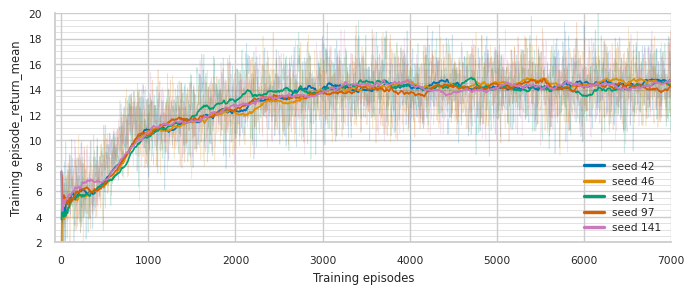

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_17kWh_seeds_return_20261028_152516_out_2.pdf  (SAC_17kWh [sac] — In-training eval return)


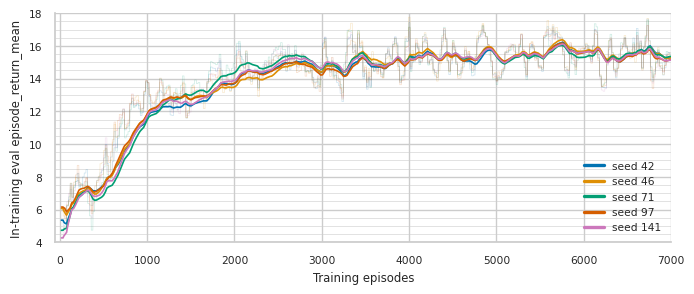


=== SAC_15kWh  [sac]  20260714_235241_gen_battery_lin_so_only_15kW_sac_cp_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_15kWh_seeds_return_20261028_152516_out_3.pdf  (SAC_15kWh [sac] — Training return)


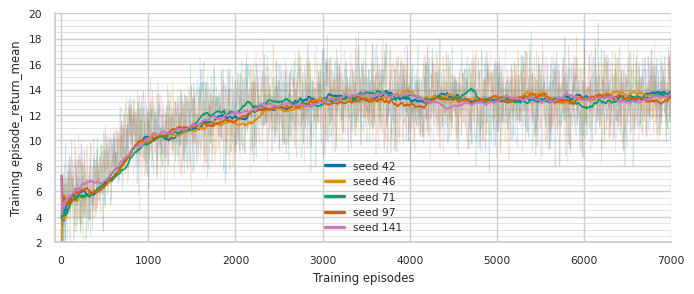

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_15kWh_seeds_return_20261028_152516_out_4.pdf  (SAC_15kWh [sac] — In-training eval return)


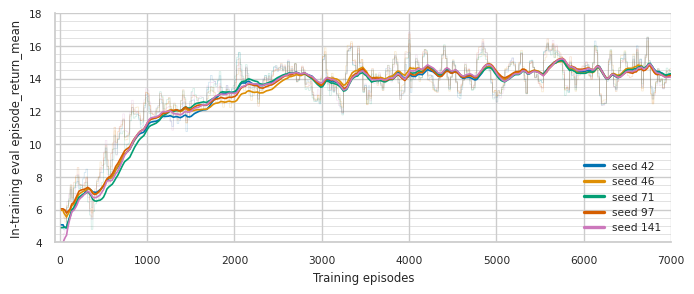


=== SAC_N-way  [sac]  20260714_162614_gen_battery_lin_so_all_sac_v2_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_N-way_seeds_return_20261028_152516_out_5.pdf  (SAC_N-way [sac] — Training return)


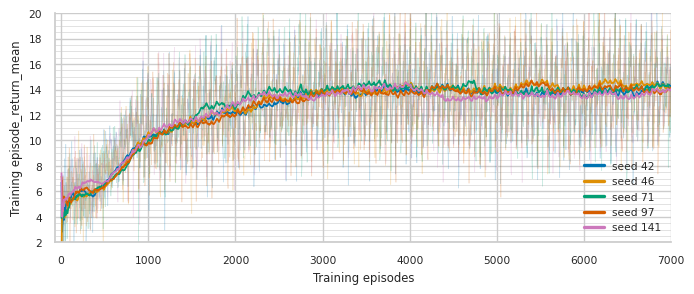

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_N-way_seeds_return_20261028_152516_out_6.pdf  (SAC_N-way [sac] — In-training eval return)


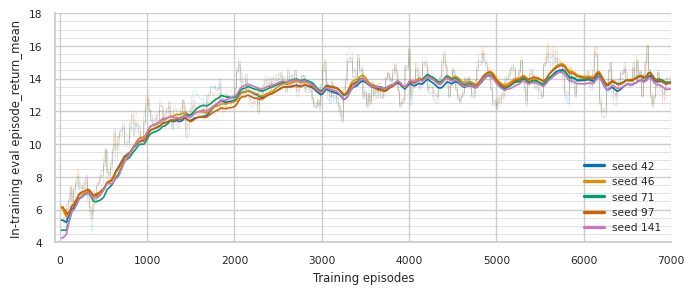


=== SAC_distr  [sac]  20260714_165943_gen_battery_lin_capacity_sampled_sac_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_distr_seeds_return_20261028_152516_out_7.pdf  (SAC_distr [sac] — Training return)


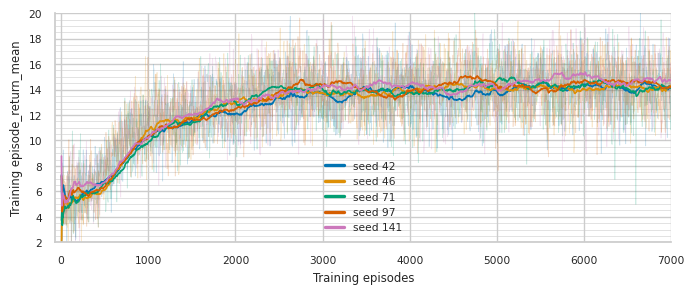

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_distr_seeds_return_20261028_152516_out_8.pdf  (SAC_distr [sac] — In-training eval return)


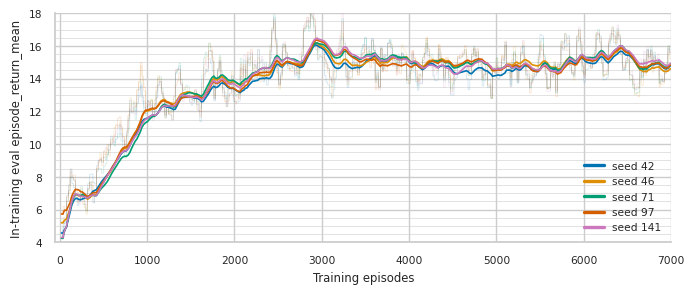


=== PPO_17kWh  [ppo]  20260714_235444_gen_battery_lin_so_only_17kW_ppo_cp_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_17kWh_seeds_return_20261028_152516_out_9.pdf  (PPO_17kWh [ppo] — Training return)


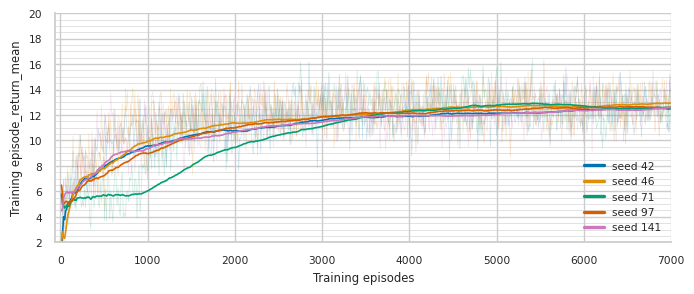

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_17kWh_seeds_return_20261028_152516_out_10.pdf  (PPO_17kWh [ppo] — In-training eval return)


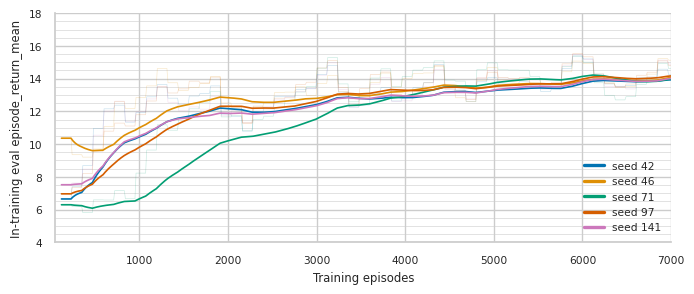


=== PPO_15kWh  [ppo]  20260714_235342_gen_battery_lin_so_only_15kW_ppo_cp_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_15kWh_seeds_return_20261028_152516_out_11.pdf  (PPO_15kWh [ppo] — Training return)


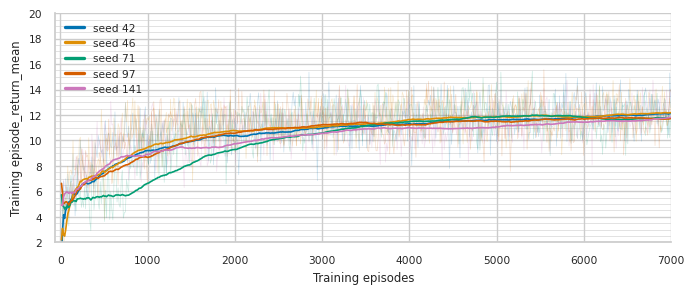

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_15kWh_seeds_return_20261028_152516_out_12.pdf  (PPO_15kWh [ppo] — In-training eval return)


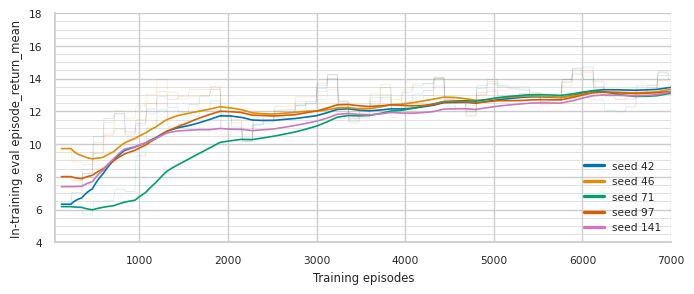


=== PPO_N-way  [ppo]  20260714_235542_gen_battery_lin_so_all_ppo_v2_cp_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_N-way_seeds_return_20261028_152516_out_13.pdf  (PPO_N-way [ppo] — Training return)


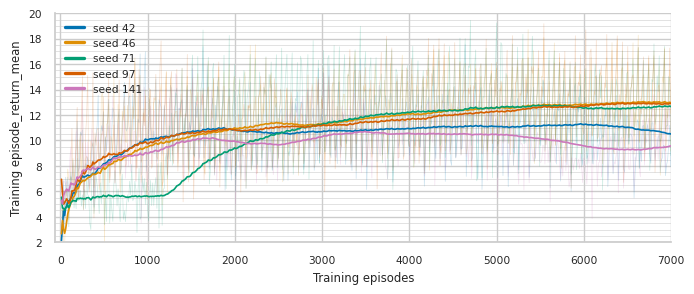

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_N-way_seeds_return_20261028_152516_out_14.pdf  (PPO_N-way [ppo] — In-training eval return)


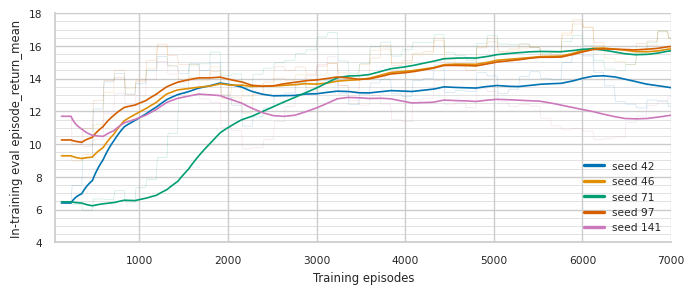


=== PPO_distr  [ppo]  20260714_235647_gen_battery_lin_capacity_sampled_ppo_cp_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_distr_seeds_return_20261028_152516_out_15.pdf  (PPO_distr [ppo] — Training return)


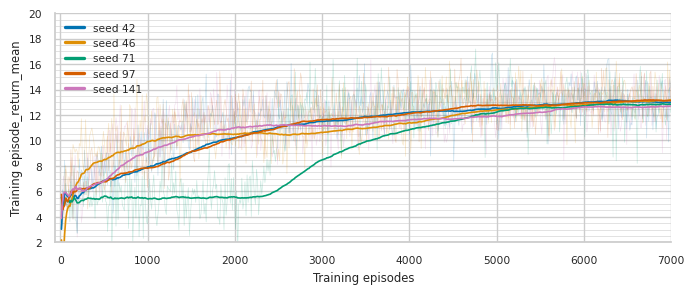

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_distr_seeds_return_20261028_152516_out_16.pdf  (PPO_distr [ppo] — In-training eval return)


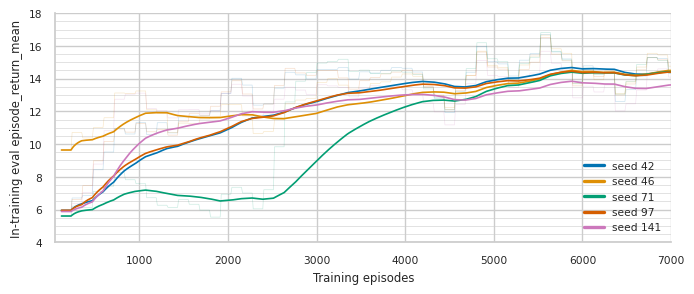


=== DreamerV3_17kWh  [dreamerv3]  20260714_225444_gen_battery_lin_so_only_17kW_dreamer_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_17kWh_seeds_return_20261028_152516_out_17.pdf  (DreamerV3_17kWh [dreamerv3] — Training return)


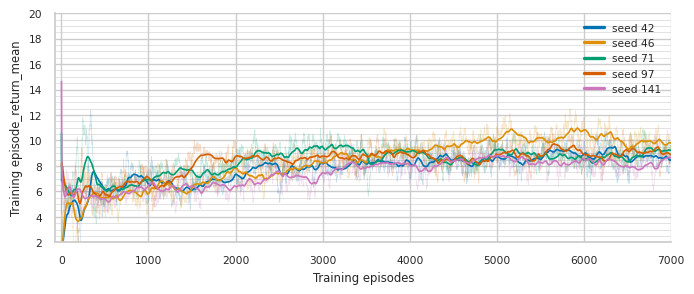

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_17kWh_seeds_return_20261028_152516_out_18.pdf  (DreamerV3_17kWh [dreamerv3] — In-training eval return)


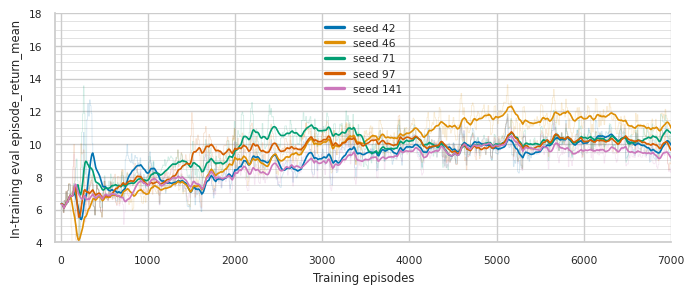


=== DreamerV3_15kWh  [dreamerv3]  20260714_225342_gen_battery_lin_so_only_15kW_dreamer_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_15kWh_seeds_return_20261028_152516_out_19.pdf  (DreamerV3_15kWh [dreamerv3] — Training return)


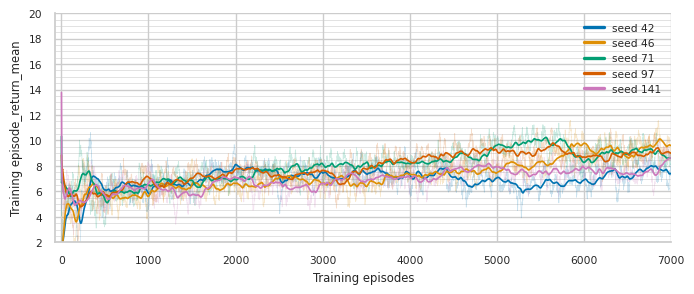

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_15kWh_seeds_return_20261028_152516_out_20.pdf  (DreamerV3_15kWh [dreamerv3] — In-training eval return)


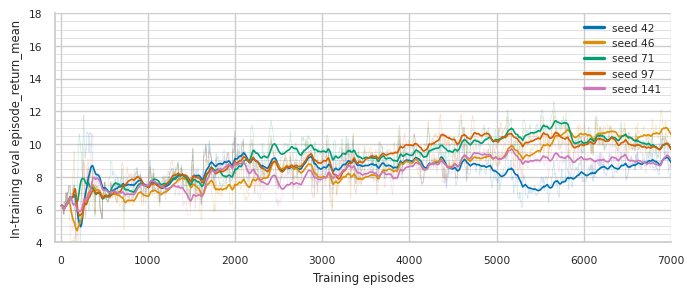


=== DreamerV3_N-way  [dreamerv3]  20260714_225542_gen_battery_lin_so_all_dreamer_v2_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_N-way_seeds_return_20261028_152516_out_21.pdf  (DreamerV3_N-way [dreamerv3] — Training return)


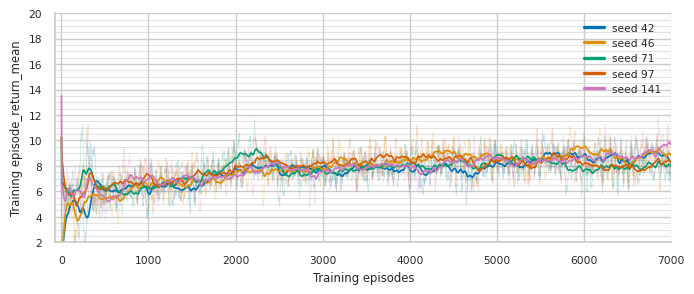

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_N-way_seeds_return_20261028_152516_out_22.pdf  (DreamerV3_N-way [dreamerv3] — In-training eval return)


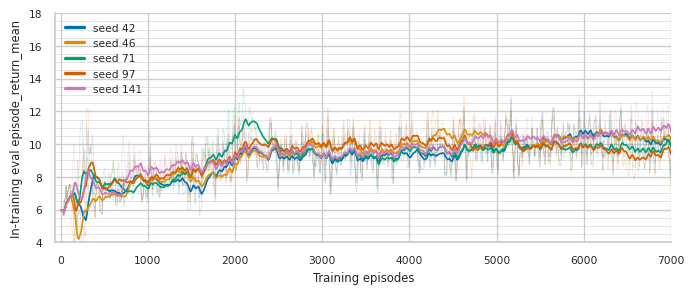


=== DreamerV3_distr  [dreamerv3]  20260714_225647_gen_battery_lin_capacity_sampled_dreamer_pp ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_distr_seeds_return_20261028_152516_out_23.pdf  (DreamerV3_distr [dreamerv3] — Training return)


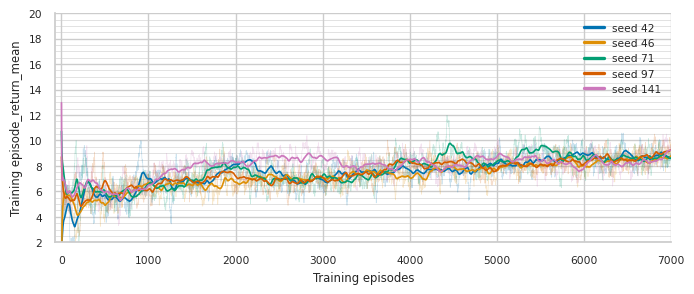

saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_distr_seeds_return_20261028_152516_out_24.pdf  (DreamerV3_distr [dreamerv3] — In-training eval return)


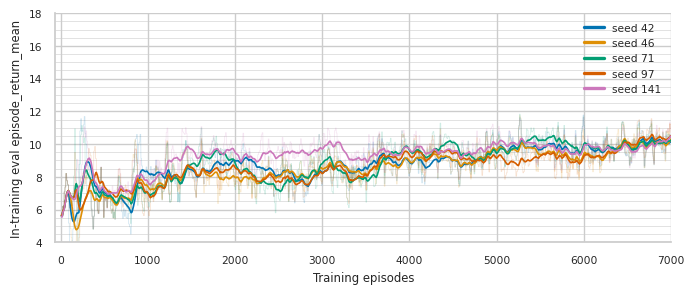

In [6]:
# Two figures per snapshot, in SNAPSHOTS order: TRAIN_METRIC first, then EVAL_METRIC.
# Per-figure y-cuts come from Y_LIMITS_DEFAULT, overridden per snapshot label by Y_LIMITS in the
# input cell, e.g. Y_LIMITS = {"PPO_N-way": {"eval": (3.0, 18.0)}}; a single figure can also be
# redrawn by hand with plot_per_seed(snapshots[i], "eval", y_min=3.0, y_max=18.0).
for snapshot in snapshots:
    print(f"\n=== {snapshot['label']}  [{snapshot['algorithm']}]  {snapshot['dir'].name} ===")
    for series_name in ("train", "eval"):
        default_limits = Y_LIMITS_DEFAULT.get(series_name, (None, None))
        y_min, y_max = Y_LIMITS.get(snapshot["label"], {}).get(series_name, default_limits)
        plot_per_seed(snapshot, series_name, y_min=y_min, y_max=y_max)


## Across-seed mean and spread

Per snapshot, its seed-wise smoothed curves are interpolated onto a common x-grid and reduced to
a mean line with a `BAND` spread, giving the training and eval curve of *that configuration*
rather than of any single run. Both series share one figure per snapshot — it exists to compare
them — while the per-seed detail lives in the two standalone figures above. The grid spans the
range every seed **of that snapshot** covers — from the largest first to the smallest last x
value — so the band is computed from all its seeds everywhere and a short run in another
snapshot cannot clip it; the printed range shows how much a short run clips off the end. Figure
size is `BAND_FIGSIZE`.

*Reading of the current list:* at the grid end (7000 episodes; 6996 for PPO) the eval mean sits
**above** the training mean in eleven of the twelve snapshots — by +0.54 to +0.76 for SAC,
+1.30 to +1.38 for PPO (+2.82 for N-way) and +0.94 to +1.42 for DreamerV3 — and below it only
for SAC N-way (−0.41). The gap is not exploration: both series are sampled with
`explore: true` (every run's `param_space.json`), because the eval override sets only
`env_config` (`common_model_config.py:266-276`). The comment above it (`:263`) says eval runs
without exploration noise, but the config does not do that. Nor is the gap the battery: the
infra schedule pushes the current *training* infra config to the eval EnvRunners as well
(`ray/callbacks/infra_schedule_callback.py:72-73`). The difference is the data: eval EnvRunners
run with `eval_mode=True`, which routes them to the held-out `data_schedule.eval` combinator
(`ray/env_creator.py:114-116`) and draws a fresh random (variant, day) per episode
(`core/_data_variant_manager.py:59`). The two curves are therefore returns on two different
data distributions — comparable in shape, not in level.

The bands at the grid end are tight for SAC (± 0.07-0.26) and PPO (± 0.09-0.37), except PPO
N-way (± 1.58 training / ± 1.86 eval, from its two low seeds), and wider for DreamerV3
(± 0.16-0.79). The means are read at the common grid end rather than at each run's own last
point, so they differ slightly from the mean of the `final_*` columns in the summary table.


=== SAC_17kWh  [sac] ===
SAC_17kWh train: x 4-7000, final mean 14.497, final spread 14.273-14.721
SAC_17kWh  eval: x 20-7000, final mean 15.253, final spread 15.161-15.345


saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_17kWh_seeds_return_20261028_152516_out_25.pdf  (SAC_17kWh [sac] — mean + ± 1 std)


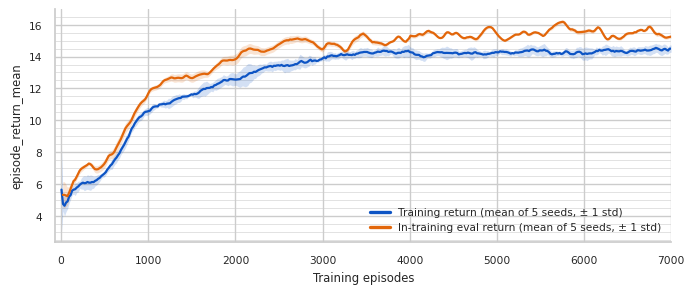


=== SAC_15kWh  [sac] ===
SAC_15kWh train: x 4-7000, final mean 13.546, final spread 13.367-13.726
SAC_15kWh  eval: x 20-7000, final mean 14.211, final spread 14.136-14.285
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_15kWh_seeds_return_20261028_152516_out_26.pdf  (SAC_15kWh [sac] — mean + ± 1 std)


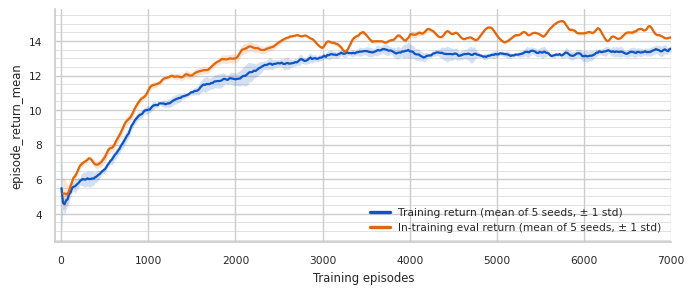


=== SAC_N-way  [sac] ===
SAC_N-way train: x 4-7000, final mean 14.101, final spread 13.989-14.213
SAC_N-way  eval: x 20-7000, final mean 13.687, final spread 13.507-13.866
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_N-way_seeds_return_20261028_152516_out_27.pdf  (SAC_N-way [sac] — mean + ± 1 std)


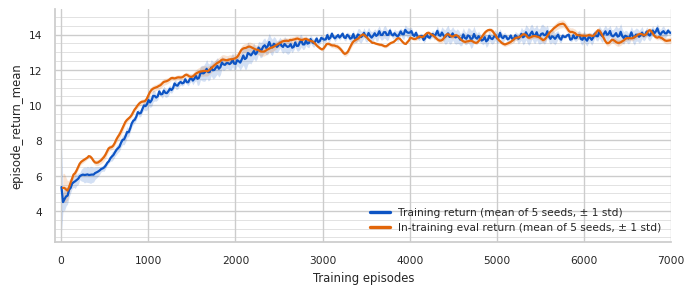


=== SAC_distr  [sac] ===
SAC_distr train: x 4-7000, final mean 14.296, final spread 14.041-14.552
SAC_distr  eval: x 20-7000, final mean 14.832, final spread 14.706-14.958
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/SAC_distr_seeds_return_20261028_152516_out_28.pdf  (SAC_distr [sac] — mean + ± 1 std)


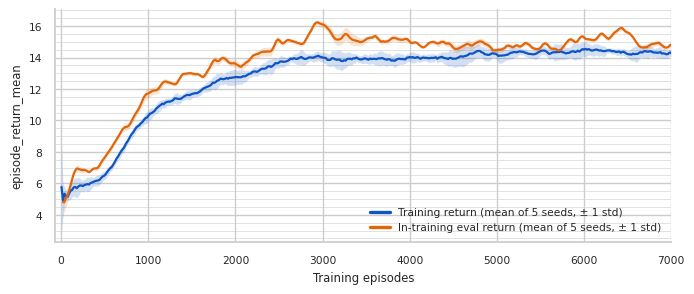


=== PPO_17kWh  [ppo] ===
PPO_17kWh train: x 12-6996, final mean 12.647, final spread 12.482-12.812
PPO_17kWh  eval: x 120-6996, final mean 14.028, final spread 13.935-14.121
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_17kWh_seeds_return_20261028_152516_out_29.pdf  (PPO_17kWh [ppo] — mean + ± 1 std)


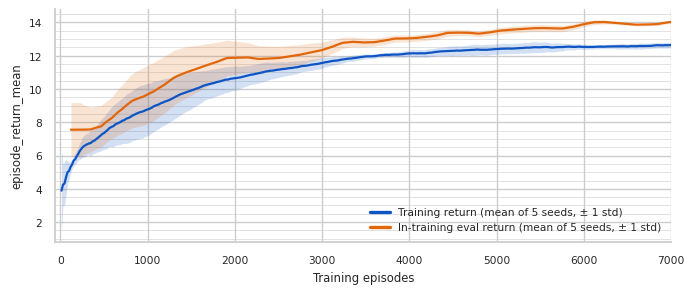


=== PPO_15kWh  [ppo] ===
PPO_15kWh train: x 12-6996, final mean 11.924, final spread 11.717-12.130
PPO_15kWh  eval: x 120-6996, final mean 13.261, final spread 13.118-13.405
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_15kWh_seeds_return_20261028_152516_out_30.pdf  (PPO_15kWh [ppo] — mean + ± 1 std)


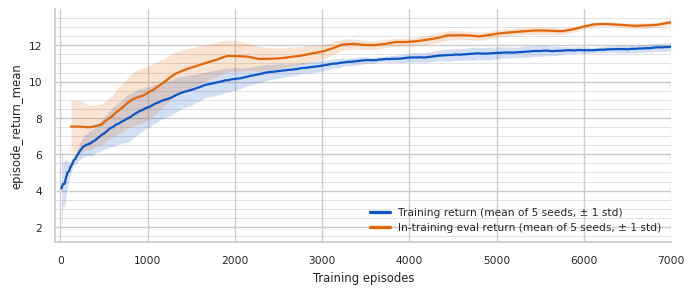


=== PPO_N-way  [ppo] ===
PPO_N-way train: x 12-6996, final mean 11.721, final spread 10.143-13.299
PPO_N-way  eval: x 120-6996, final mean 14.539, final spread 12.675-16.402
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_N-way_seeds_return_20261028_152516_out_31.pdf  (PPO_N-way [ppo] — mean + ± 1 std)


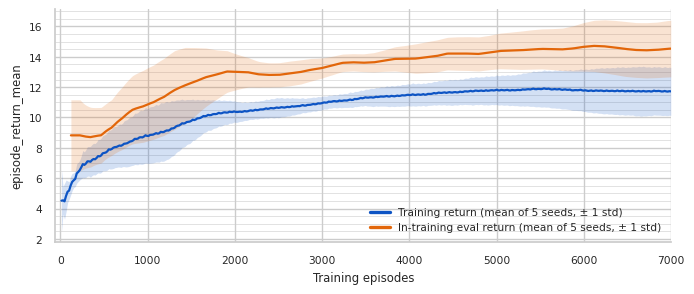


=== PPO_distr  [ppo] ===
PPO_distr train: x 12-6996, final mean 12.972, final spread 12.776-13.168
PPO_distr  eval: x 120-6996, final mean 14.277, final spread 13.905-14.648
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/PPO_distr_seeds_return_20261028_152516_out_32.pdf  (PPO_distr [ppo] — mean + ± 1 std)


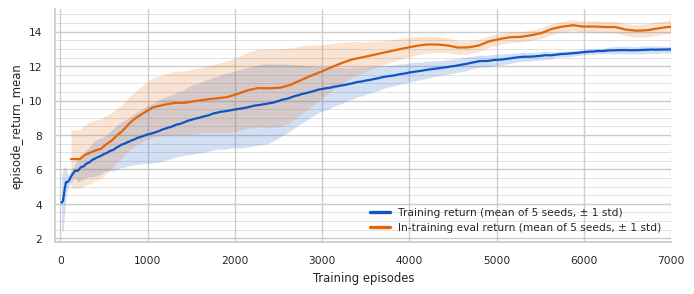


=== DreamerV3_17kWh  [dreamerv3] ===
DreamerV3_17kWh train: x 1-7000, final mean 9.000, final spread 8.481-9.520
DreamerV3_17kWh  eval: x 10-7000, final mean 10.071, final spread 9.319-10.823
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_17kWh_seeds_return_20261028_152516_out_33.pdf  (DreamerV3_17kWh [dreamerv3] — mean + ± 1 std)


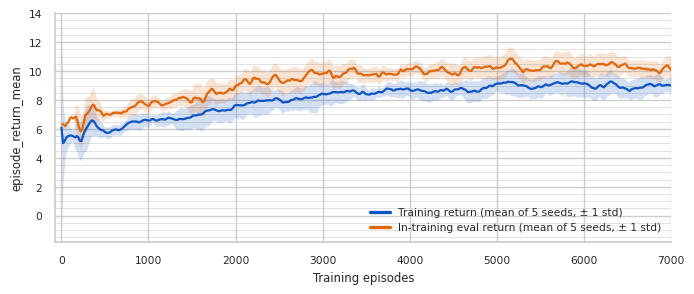


=== DreamerV3_15kWh  [dreamerv3] ===
DreamerV3_15kWh train: x 1-7000, final mean 8.645, final spread 7.853-9.436
DreamerV3_15kWh  eval: x 10-7000, final mean 9.581, final spread 8.918-10.245
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_15kWh_seeds_return_20261028_152516_out_34.pdf  (DreamerV3_15kWh [dreamerv3] — mean + ± 1 std)


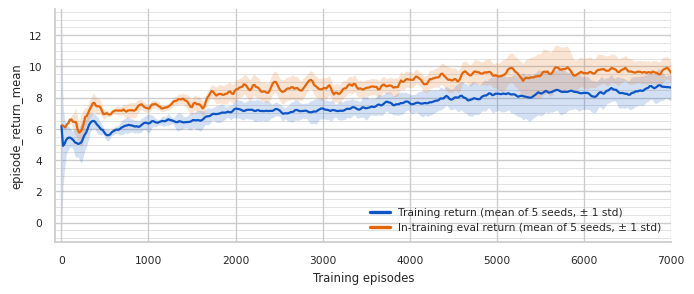


=== DreamerV3_N-way  [dreamerv3] ===
DreamerV3_N-way train: x 1-7000, final mean 8.610, final spread 7.938-9.282
DreamerV3_N-way  eval: x 10-7000, final mean 10.001, final spread 9.503-10.498
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_N-way_seeds_return_20261028_152516_out_35.pdf  (DreamerV3_N-way [dreamerv3] — mean + ± 1 std)


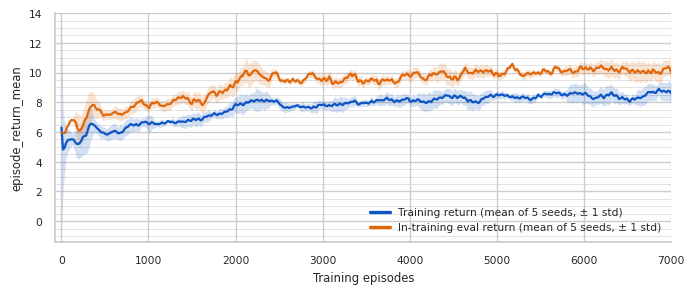


=== DreamerV3_distr  [dreamerv3] ===
DreamerV3_distr train: x 1-7000, final mean 8.923, final spread 8.623-9.223
DreamerV3_distr  eval: x 10-7000, final mean 10.341, final spread 10.179-10.503
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/DreamerV3_distr_seeds_return_20261028_152516_out_36.pdf  (DreamerV3_distr [dreamerv3] — mean + ± 1 std)


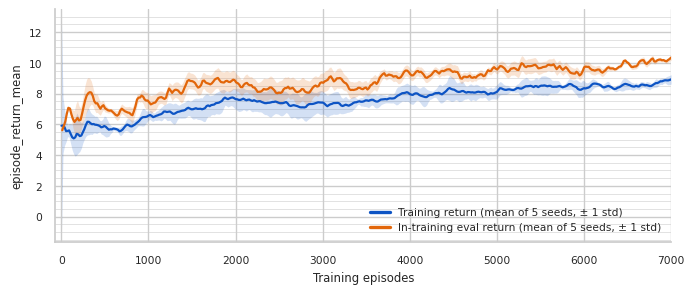

In [7]:
BAND_GRID_POINTS = 400


# Mean and spread of one snapshot's per-seed smoothed curves on a shared x-grid. The grid is
# built from that snapshot's runs only, so a short run in another snapshot cannot clip it.
def _aggregate(snapshot: dict, series_name: str) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, str]:
    x_per_seed, y_per_seed, x_label = [], [], ""
    for record in snapshot["records"]:
        x_values, x_label = _x_values(record, record["curves"][series_name])
        x_per_seed.append(x_values)
        y_per_seed.append(record[f"smoothed_{series_name}"])

    grid_start = max(float(x_values[0]) for x_values in x_per_seed)
    grid_end = min(float(x_values[-1]) for x_values in x_per_seed)
    grid = np.linspace(grid_start, grid_end, BAND_GRID_POINTS)
    stacked = np.vstack([
        np.interp(grid, x_values, y_values) for x_values, y_values in zip(x_per_seed, y_per_seed)
    ])

    mean = stacked.mean(axis=0)
    if BAND == "std":
        deviation = stacked.std(axis=0, ddof=1) if len(stacked) > 1 else np.zeros_like(mean)
        lower, upper = mean - deviation, mean + deviation
    elif BAND == "minmax":
        lower, upper = stacked.min(axis=0), stacked.max(axis=0)
    elif BAND == "iqr":
        lower, upper = np.percentile(stacked, 25, axis=0), np.percentile(stacked, 75, axis=0)
    else:
        raise ValueError(f"BAND must be 'std', 'minmax' or 'iqr', got {BAND!r}")
    return grid, mean, lower, upper, x_label


BAND_LABELS = {"std": "± 1 std", "minmax": "min-max", "iqr": "IQR"}


# One aggregate figure per snapshot, carrying that snapshot's two series.
def plot_seed_band(snapshot: dict) -> None:
    fig, ax = plt.subplots(figsize=BAND_FIGSIZE)
    x_label = ""
    for series_name, color in (("train", TRAIN_COLOR), ("eval", EVAL_COLOR)):
        grid, mean, lower, upper, x_label = _aggregate(snapshot, series_name)
        ax.fill_between(grid, lower, upper, color=color, alpha=0.18, linewidth=0.0, zorder=1)
        ax.plot(grid, mean, color=color, linewidth=1.6,
                label=f"{SERIES_LABELS[series_name]} (mean of {len(snapshot['records'])} seeds, {BAND_LABELS[BAND]})",
                zorder=2)
        print(f"{snapshot['label']} {series_name:>5}: x {grid[0]:.0f}-{grid[-1]:.0f}, final mean {mean[-1]:.3f}, "
              f"final spread {lower[-1]:.3f}-{upper[-1]:.3f}")

    ax.set_xlabel(x_label)
    ax.set_ylabel("episode_return_mean")
    ax.margins(x=0.01)
    _apply_y_ticks(ax)
    _apply_x_limit(ax)
    legend = ax.legend(title="", frameon=False, loc="lower right", handlelength=1.8, fontsize=LEGEND_FONTSIZE)
    for handle in legend.get_lines():
        handle.set_linewidth(2.4)
    sns.despine(ax=ax)
    fig.tight_layout()

    pdf_path = next_out_path(snapshot["label"], "pdf")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"saved {pdf_path}  ({snapshot['label']} [{snapshot['algorithm']}] — mean + {BAND_LABELS[BAND]})")
    plt.show()


for snapshot in snapshots:
    print(f"\n=== {snapshot['label']}  [{snapshot['algorithm']}] ===")
    plot_seed_band(snapshot)

## Across-method comparison — one figure per training config

The only figures in this notebook that put **different snapshots on a single axes**: one figure
per training config (the `config` key of the `SNAPSHOTS` entries) and series, each carrying the
across-seed mean line plus `BAND` spread of every method trained on that config. The training
return figures come first, the in-training eval ones in the next cell. The per-snapshot figure
above compares the two *series* of one snapshot; these compare one series across the methods of
one config.

Reductions are reused verbatim: `_aggregate(snapshot, series)` is the same function the
per-snapshot band figure calls, so a method's mean and band here are identical to the ones it
draws there — nothing is re-smoothed, re-gridded or re-averaged for these plots. Consequently
**each method keeps its own x-grid**, spanning only what all of *its* seeds cover (largest
first to smallest last x value), so a snapshot whose runs stopped early would end early instead
of truncating the others. The printed range per method makes that explicit, and `X_MAX` keeps
the horizontal extent fixed.

**Why one figure per training config.** Return levels are only comparable between snapshots
that share a trial config — the same env, rewards and data schedule — and differ in the
algorithm alone. For the GEN snapshots in `SNAPSHOTS` this was checked per config: the frozen
`code/` of its SAC, PPO and DreamerV3 snapshots differs only in the trial YAML, and the trial
YAML (with the infra and schedule YAMLs it references) only in `algorithm`, `trial_name` and the
algorithm-specific `training_params` sections. Across configs the training env itself differs
(one battery capacity, several, or a sampled one), so levels are not comparable *between* these
figures. The notebook cannot check a new `config` grouping, so that is on the reader; it does
reject a config that lists the same algorithm twice, since those two lines would share a colour.

Colours key **methods** (`METHOD_COLORS`, keyed by the algorithm read off the filesystem), the
same in every comparison figure and the same as the method colours of
`sps_eval_violins_seed_compare.ipynb`; the seed palettes of the per-seed figures and the
`TRAIN_COLOR`/`EVAL_COLOR` pair of the per-snapshot band figure are left untouched.
`COMPARE_YLIM` cuts the y-axis of these figures per series. Note also that the x-axis unit is
whatever `X_AXIS` selects for all of them at once; on `"episodes"` the methods are compared at
equal *sample* budget, which is not equal wall clock. There is no wall-clock counterpart for
these snapshots; `../2_base_bat_rbc_vs_rl/sps_train_return_convergence_time.ipynb` is the one
for the base-battery snapshots.

*Reading of the current list:* at the grid end SAC leads in training return on every config
(13.55-14.50, vs 11.72-12.97 for PPO and 8.61-9.00 for DreamerV3). It also leads in eval return
on 17 kWh, 15 kWh and distr, by 0.55-1.22. On N-way, PPO's eval mean ends above SAC's (14.54 vs
13.69), but with ± 1.86 across its seeds. DreamerV3 ends lowest on every config in both series
(eval 9.58-10.34).

**Convergence speed is distorted by the smoothing.** The `SMOOTHING` EWMA averages over roughly
the last 1 / (1 − 0.99) = 100 logged *steps*, which is ≈ 200 episodes for SAC, ≈ 1200 for PPO
and ≈ 100 for DreamerV3, so in these figures PPO's curves trail their data the most and look
slower than they are. Measured on the raw logged means, averaged over the seeds and a common
250-episode window, the training mean first reaches 90 % of its end level after 1320-1690
episodes for PPO (2760 on distr), 1800-2160 for SAC and 2080-4340 for DreamerV3.



=== 17kWh — Training return ===
       SAC_17kWh        SAC (5 seeds): x 4-7000, final mean 14.497, final spread 14.273-14.721 (+/-0.224)
       PPO_17kWh        PPO (5 seeds): x 12-6996, final mean 12.647, final spread 12.482-12.812 (+/-0.165)
 DreamerV3_17kWh  DreamerV3 (5 seeds): x 1-7000, final mean 9.000, final spread 8.481-9.520 (+/-0.520)


saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_17kWh_seeds_return_20261028_152516_out_37.pdf  (17kWh: 3 methods — Training return, mean + ± 1 std)


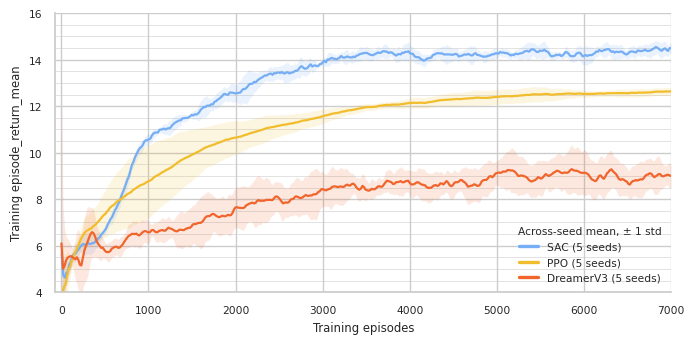


=== 15kWh — Training return ===
       SAC_15kWh        SAC (5 seeds): x 4-7000, final mean 13.546, final spread 13.367-13.726 (+/-0.179)
       PPO_15kWh        PPO (5 seeds): x 12-6996, final mean 11.924, final spread 11.717-12.130 (+/-0.206)
 DreamerV3_15kWh  DreamerV3 (5 seeds): x 1-7000, final mean 8.645, final spread 7.853-9.436 (+/-0.792)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_15kWh_seeds_return_20261028_152516_out_38.pdf  (15kWh: 3 methods — Training return, mean + ± 1 std)


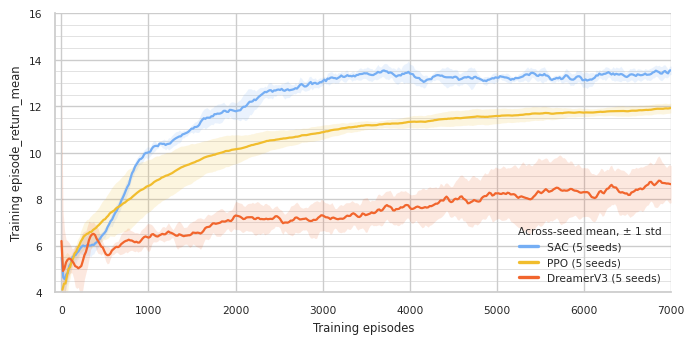


=== N-way — Training return ===
       SAC_N-way        SAC (5 seeds): x 4-7000, final mean 14.101, final spread 13.989-14.213 (+/-0.112)
       PPO_N-way        PPO (5 seeds): x 12-6996, final mean 11.721, final spread 10.143-13.299 (+/-1.578)
 DreamerV3_N-way  DreamerV3 (5 seeds): x 1-7000, final mean 8.610, final spread 7.938-9.282 (+/-0.672)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_N-way_seeds_return_20261028_152516_out_39.pdf  (N-way: 3 methods — Training return, mean + ± 1 std)


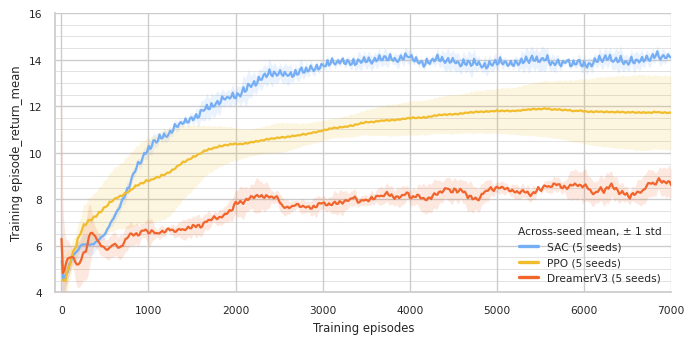


=== distr — Training return ===
       SAC_distr        SAC (5 seeds): x 4-7000, final mean 14.296, final spread 14.041-14.552 (+/-0.255)
       PPO_distr        PPO (5 seeds): x 12-6996, final mean 12.972, final spread 12.776-13.168 (+/-0.196)
 DreamerV3_distr  DreamerV3 (5 seeds): x 1-7000, final mean 8.923, final spread 8.623-9.223 (+/-0.300)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_distr_seeds_return_20261028_152516_out_40.pdf  (distr: 3 methods — Training return, mean + ± 1 std)


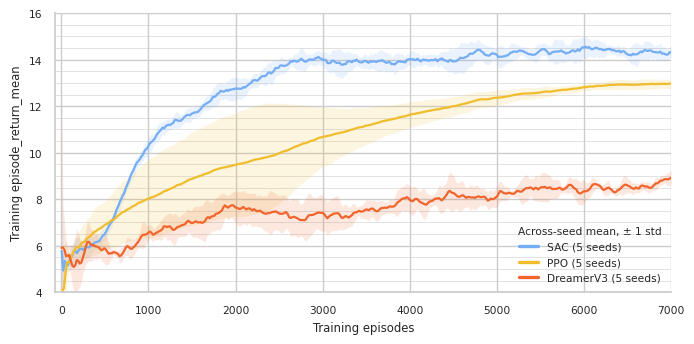

In [8]:
# --- Across-method comparison figures -----------------------------------------------
# Y-axis cut of the comparison figures per series, (y_min, y_max); either bound may be None to
# leave that side to matplotlib. Deliberately separate from Y_LIMITS_DEFAULT: those cuts are set
# for the per-seed RAW curves, whose range is wider than that of the across-seed means drawn
# here. Past the first 300 episodes every mean +/- band lies within 5.0-15.1 (training) and
# 5.1-16.4 (eval); the training cut only hides the first-episodes dip (DreamerV3 band down to -1.1).
COMPARE_YLIM: dict[str, tuple[float | None, float | None]] = {
    "train": (4.0, 16.0),
    "eval": (4.0, 18.0),
}

# Whether the spread band is filled behind each mean. False leaves the mean lines alone, which
# is the readable fallback once enough methods overlap for the bands to muddy each other.
COMPARE_SHOW_BAND = True

COMPARE_FIGSIZE = (7.0, 3.5)

# Filename label of the saved figures; the training config is appended per figure.
COMPARE_OUT_LABEL = "methods"

# One colour per method, keyed by the algorithm id Ray stored the run under
# (models/<trial>/ray/<algo>, run_train_ray.py:365) and shared by every comparison figure, so a
# method keeps its colour across training configs. Same colours as the METHOD palette of
# sps_eval_violins_seed_compare.ipynb. An algorithm not listed gets a "colorblind" colour.
# Link: https://seaborn.pydata.org/generated/seaborn.color_palette.html
METHOD_COLORS: dict[str, str] = {"sac": "#75aef4", "ppo": "#f1bd2d", "dreamerv3": "#f1652d"}
METHOD_LABELS = {"sac": "SAC", "ppo": "PPO", "dreamerv3": "DreamerV3"}

_unlisted_algorithms = sorted({snapshot["algorithm"] for snapshot in snapshots} - set(METHOD_COLORS))
METHOD_PALETTE = dict(zip(_unlisted_algorithms, sns.color_palette("colorblind", len(_unlisted_algorithms)))) | METHOD_COLORS

# Snapshots per training config, both in SNAPSHOTS order. Each config becomes one figure per
# series, so its methods must be distinct — two snapshots of one algorithm would share a colour.
COMPARE_GROUPS: dict[str, list[dict]] = {}
for snapshot in snapshots:
    if snapshot["config"] is None:
        print(f"note: {snapshot['label']} has no 'config' key in SNAPSHOTS — left out of the method comparison")
        continue
    COMPARE_GROUPS.setdefault(snapshot["config"], []).append(snapshot)
for config, members in COMPARE_GROUPS.items():
    member_algorithms = [snapshot["algorithm"] for snapshot in members]
    if len(member_algorithms) != len(set(member_algorithms)):
        raise ValueError(f"Training config {config!r} lists an algorithm twice ({member_algorithms}) — "
                         "its methods would share a colour")


# Legend entry of one method: the method name read off the filesystem plus its seed count.
def _method_legend(snapshot: dict) -> str:
    return f"{METHOD_LABELS.get(snapshot['algorithm'], snapshot['algorithm'])} ({len(snapshot['records'])} seeds)"


# One figure carrying the across-seed mean of `series_name` for every snapshot of training
# config `config`, each with its own spread band. The per-method reduction is `_aggregate` — the
# same call the per-snapshot band figure makes — so each method keeps its OWN x-grid and a
# snapshot whose seeds stopped early simply ends early instead of clipping the others.
#
# `y_min` / `y_max` cut the y-axis for this figure alone (the drivers pass COMPARE_YLIM);
# curves are clipped, not dropped.
def plot_method_comparison(config: str, series_name: str,
                           y_min: float | None = None, y_max: float | None = None) -> None:
    fig, ax = plt.subplots(figsize=COMPARE_FIGSIZE)
    x_label = ""
    for snapshot in COMPARE_GROUPS[config]:
        grid, mean, lower, upper, x_label = _aggregate(snapshot, series_name)
        color = METHOD_PALETTE[snapshot["algorithm"]]
        if COMPARE_SHOW_BAND:
            ax.fill_between(grid, lower, upper, color=color, alpha=0.15, linewidth=0.0, zorder=1)
        ax.plot(grid, mean, color=color, linewidth=1.6, label=_method_legend(snapshot), zorder=2)
        print(f"{snapshot['label']:>16} {_method_legend(snapshot):>20}: x {grid[0]:.0f}-{grid[-1]:.0f}, "
              f"final mean {mean[-1]:.3f}, final spread {lower[-1]:.3f}-{upper[-1]:.3f} "
              f"(+/-{(upper[-1] - mean[-1]):.3f})")

    ax.set_xlabel(x_label)
    ax.set_ylabel(Y_LABELS[series_name])
    ax.margins(x=0.01)
    if y_min is not None or y_max is not None:
        ax.set_ylim(bottom=y_min, top=y_max)
    # After the limits are final, so the ticks cover exactly the drawn range.
    _apply_y_ticks(ax)
    _apply_x_limit(ax)
    legend = ax.legend(title=f"Across-seed mean, {BAND_LABELS[BAND]}", frameon=False,
                       loc="lower right", handlelength=1.8, fontsize=LEGEND_FONTSIZE)
    legend.get_title().set_fontsize(legend_pt)
    for handle in legend.get_lines():
        handle.set_linewidth(2.4)
    sns.despine(ax=ax)
    fig.tight_layout()

    pdf_path = next_out_path(f"{COMPARE_OUT_LABEL}_{config}", "pdf")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"saved {pdf_path}  ({config}: {len(COMPARE_GROUPS[config])} methods — "
          f"{SERIES_LABELS[series_name]}, mean + {BAND_LABELS[BAND]})")
    plt.show()


for config in COMPARE_GROUPS:
    print(f"\n=== {config} — {SERIES_LABELS['train']} ===")
    plot_method_comparison(config, "train", *COMPARE_YLIM["train"])



=== 17kWh — In-training eval return ===


       SAC_17kWh        SAC (5 seeds): x 20-7000, final mean 15.253, final spread 15.161-15.345 (+/-0.092)
       PPO_17kWh        PPO (5 seeds): x 120-6996, final mean 14.028, final spread 13.935-14.121 (+/-0.093)
 DreamerV3_17kWh  DreamerV3 (5 seeds): x 10-7000, final mean 10.071, final spread 9.319-10.823 (+/-0.752)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_17kWh_seeds_return_20261028_152516_out_41.pdf  (17kWh: 3 methods — In-training eval return, mean + ± 1 std)


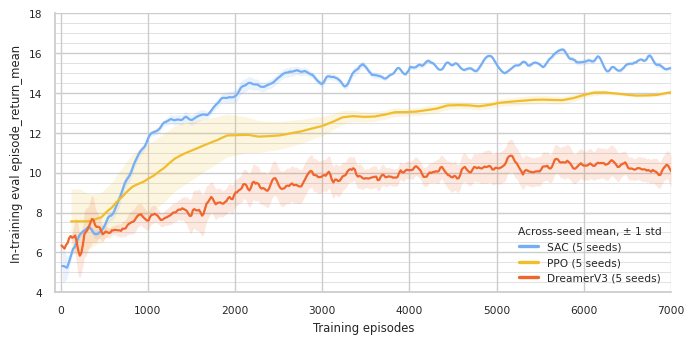


=== 15kWh — In-training eval return ===
       SAC_15kWh        SAC (5 seeds): x 20-7000, final mean 14.211, final spread 14.136-14.285 (+/-0.075)
       PPO_15kWh        PPO (5 seeds): x 120-6996, final mean 13.261, final spread 13.118-13.405 (+/-0.144)
 DreamerV3_15kWh  DreamerV3 (5 seeds): x 10-7000, final mean 9.581, final spread 8.918-10.245 (+/-0.663)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_15kWh_seeds_return_20261028_152516_out_42.pdf  (15kWh: 3 methods — In-training eval return, mean + ± 1 std)


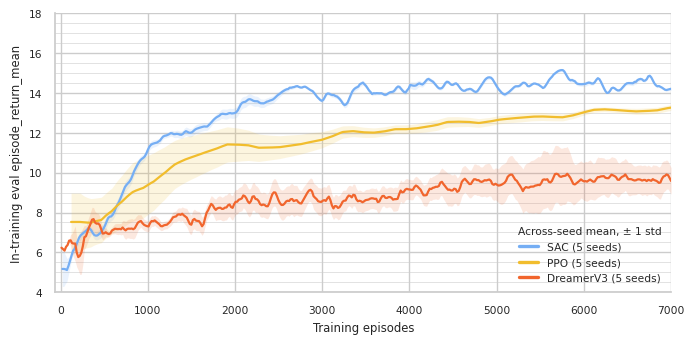


=== N-way — In-training eval return ===
       SAC_N-way        SAC (5 seeds): x 20-7000, final mean 13.687, final spread 13.507-13.866 (+/-0.179)
       PPO_N-way        PPO (5 seeds): x 120-6996, final mean 14.539, final spread 12.675-16.402 (+/-1.864)
 DreamerV3_N-way  DreamerV3 (5 seeds): x 10-7000, final mean 10.001, final spread 9.503-10.498 (+/-0.497)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_N-way_seeds_return_20261028_152516_out_43.pdf  (N-way: 3 methods — In-training eval return, mean + ± 1 std)


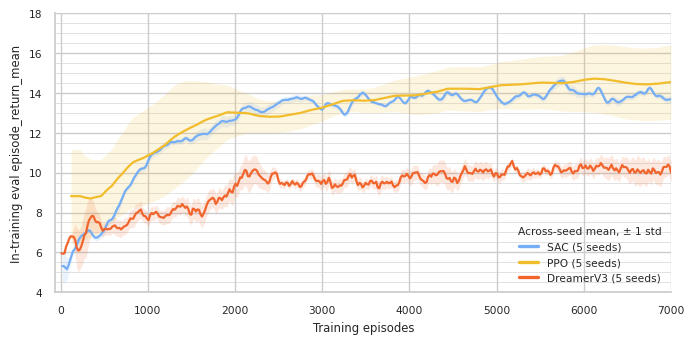


=== distr — In-training eval return ===
       SAC_distr        SAC (5 seeds): x 20-7000, final mean 14.832, final spread 14.706-14.958 (+/-0.126)
       PPO_distr        PPO (5 seeds): x 120-6996, final mean 14.277, final spread 13.905-14.648 (+/-0.372)
 DreamerV3_distr  DreamerV3 (5 seeds): x 10-7000, final mean 10.341, final spread 10.179-10.503 (+/-0.162)
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/methods_distr_seeds_return_20261028_152516_out_44.pdf  (distr: 3 methods — In-training eval return, mean + ± 1 std)


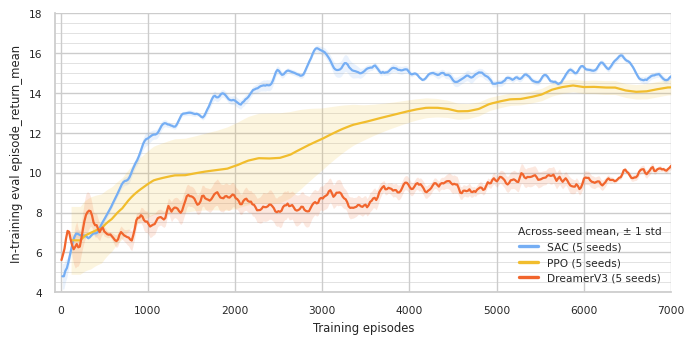

In [9]:
for config in COMPARE_GROUPS:
    print(f"\n=== {config} — {SERIES_LABELS['eval']} ===")
    plot_method_comparison(config, "eval", *COMPARE_YLIM["eval"])


## Seed spread of the converged return

`mean` / `std` / `min` / `max` across the per-seed end-of-training values from the summary
table, **one block per snapshot**: how much of the final return is seed noise rather than the
configuration. `final_train` and `final_eval` are smoothed (so they read the converged level,
not the last noisy point), `max_eval` is the raw best eval round each seed reached. Levels
compare between the methods of one training config, which share env, rewards and data (see the
comparison section), but not between configs, whose training envs differ.

In [10]:
spread = pd.concat(
    {snapshot["label"]: snapshot["summary"][["final_train", "final_eval", "max_eval"]].agg(["mean", "std", "min", "max"])
     for snapshot in snapshots},
    names=["snapshot", "stat"],
).round(3)
spread

final_train  final_eval  max_eval
snapshot        stat                                   
SAC_17kWh       mean       14.497      15.253    17.494
                std         0.224       0.093     0.222
                min        14.263      15.137    17.245
                max        14.787      15.361    17.756
SAC_15kWh       mean       13.546      14.211    16.618
                std         0.179       0.074     0.156
                min        13.361      14.103    16.479
                max        13.742      14.305    16.839
SAC_N-way       mean       14.101      13.687    15.978
                std         0.112       0.179     0.159
                min        13.953      13.373    15.754
                max        14.253      13.815    16.173
SAC_distr       mean       14.296      14.832    18.125
                std         0.255       0.126     0.288
                min        14.089      14.624    17.885
                max        14.722      14.944    18.524
PPO_17kWh       mean       12.647      14.028    15.400
                std         0.165       0.093     0.118
                min        12.502      13.930    15.224
                max        12.930      14.166    15.532
PPO_15kWh       mean       11.924      13.261    14.515
                std         0.206       0.143     0.139
                min        11.728      13.100    14.335
                max        12.179      13.461    14.709
PPO_N-way       mean       11.721      14.539    16.573
                std         1.577       1.864     0.999
                min         9.564      11.765    15.333
                max        12.965      15.963    17.600
PPO_distr       mean       12.972      14.276    16.472
                std         0.196       0.372     0.460
                min        12.706      13.615    15.673
                max        13.175      14.501    16.820
DreamerV3_17kWh mean        9.000      10.071    12.698
                std         0.520       0.752     0.898
                min         8.468       9.144    11.690
                max         9.782      10.981    13.628
DreamerV3_15kWh mean        8.645       9.581    11.846
                std         0.792       0.663     0.612
                min         7.415       8.879    10.918
                max         9.576      10.577    12.597
DreamerV3_N-way mean        8.610      10.001    12.885
                std         0.672       0.498     0.432
                min         7.973       9.386    12.267
                max         9.670      10.721    13.345
DreamerV3_distr mean        8.923      10.341    11.703
                std         0.300       0.162     0.113
                min         8.624      10.148    11.553
                max         9.246      10.521    11.832

## Return at every 500th episode — per seed and across seeds

Every seed's return read at fixed training-episode checkpoints (`CHECKPOINT_EVERY` = 500, 1000,
…, up to the budget), next to the across-seed `mean` / `std` / `median` / `min` / `max` and `n`,
the number of seeds that contributed. One table per series (training, in-training eval), indexed
by `(episode, snapshot)`, so the methods sit directly under one another at every checkpoint.
Both tables are also saved as CSV next to this notebook.

- **Episode axis:** the same one the figures use, TBX step × the run's `episodes_per_step`, and
  already cut at `MAX_EPISODES`.
- **Value per seed:** the last point logged **at or before** the checkpoint — never interpolated
  and never a later point. A seed whose (cut) run ends more than one logging interval before a
  checkpoint contributes nothing there rather than an extrapolated value, which is what `n` counts;
  a checkpoint no seed of a snapshot reaches is left out of that snapshot's rows. Every run of the
  current list reaches its budget, so `n` is 5 in every row. PPO's last in-budget iteration lands
  at ≈ 6995 episodes, within one logging interval of 7000, so it still fills the 7000 row.
- **Smoothed values** (`CHECKPOINT_VALUES = "smoothed"`, the current setting): the `SMOOTHING`
  EWMA drawn in the figures. It runs per logged **step** and averages over roughly the last
  1 / (1 − `SMOOTHING`) = 100 steps, and one step is ≈ 2 episodes for SAC, ≈ 12 for PPO and 1 for
  DreamerV3 (the measured `episodes_per_step`). A smoothed value at a fixed episode therefore
  trails the data by ≈ 200, ≈ 1200 and ≈ 100 episodes respectively, so the early rows understate
  PPO the most. `CHECKPOINT_VALUES = "raw"` reads the logged `episode_return_mean` instead,
  which is already RLlib's windowed episode mean: each EnvRunner logs `EPISODE_RETURN_MEAN` with
  `window = ceil(metrics_num_episodes_for_smoothing / num_env_runners)`
  (`ray/rllib/env/single_agent_env_runner.py:886-901`, installed ray 2.52.1), and
  `metrics_num_episodes_for_smoothing` is 30 in every run's `param_space.json`. Its lag in
  episodes is about the same for every method.
- **`std`** is the sample standard deviation (`ddof=1`), as in the band figures.
- **Eval rows: seeds share their data, methods do not.** All 60 runs, the base seed-42 runs
  included, keep the top-level `seed: 42` in their trial YAML (`--common-seed` rewrites only
  `training_params.common.seed`). The eval env is seeded from that value once, at construction
  (`"seed": trial.seed` in `run_train_ray.py:369` → `ray/env_creator.py:128-129`), and in eval
  mode it ignores every later reset seed (`core/env.py:273`). All seeds of one snapshot therefore
  draw the same (variant, day) sequence round by round, and the data agree: the round-to-round
  changes of the eval return correlate at r = 0.83-0.96 between the seeds of a snapshot (0.67 for
  PPO N-way), against −0.07 to +0.18 when one seed is shifted by a round. Within a row, the eval
  `std` is the spread of the policies on identical data. Between methods, the same checkpoint
  falls on a different eval round (one round every `evaluation_interval` = 10 iterations, i.e.
  ≈ 20 episodes for SAC, ≈ 120 for PPO and ≈ 10 for DreamerV3), so different days were drawn. A
  single eval row can favour one method just because its days were easier, so compare methods
  over several checkpoints.

With five seeds per snapshot (four `--common-seed` fan-outs plus the base snapshot's seed 42),
`median` and `mean` diverge as soon as a single seed separates from the pack — that divergence is
the thing to look for when a mean looks off, PPO N-way with its two low seeds being the case in
point.

In [11]:
# --- Return at every CHECKPOINT_EVERY-th episode ---------------------------------------
# Checkpoint spacing in training episodes: 500 reads every seed at episode 500, 1000, ...
CHECKPOINT_EVERY = 500

# "raw" reads RLlib's logged episode_return_mean (itself a windowed episode mean); "smoothed"
# reads the SMOOTHING EWMA drawn in the figures, whose lag in episodes differs per method.
CHECKPOINT_VALUES = "smoothed"

CHECKPOINT_STATS = ["mean", "std", "median", "min", "max"]


# One run's value of `series_name` at every checkpoint: the last point logged at or before it.
# NaN where the run has no point yet, or where its (MAX_EPISODES-cut) curve ends more than one
# logging interval before the checkpoint — i.e. the run never got there.
def _values_at_checkpoints(record: dict, series_name: str, checkpoints: np.ndarray) -> np.ndarray:
    curve = record["curves"][series_name]
    episodes = curve["step"].to_numpy(dtype=float) * record["scales"]["episodes_per_step"]
    if CHECKPOINT_VALUES == "raw":
        values = curve["value"].to_numpy(dtype=float)
    elif CHECKPOINT_VALUES == "smoothed":
        values = record[f"smoothed_{series_name}"]
    else:
        raise ValueError(f"CHECKPOINT_VALUES must be 'raw' or 'smoothed', got {CHECKPOINT_VALUES!r}")
    logging_interval = float(np.median(np.diff(episodes))) if len(episodes) > 1 else 0.0
    last_index = np.searchsorted(episodes, checkpoints, side="right") - 1
    reached = (last_index >= 0) & (checkpoints - episodes[-1] <= logging_interval)
    return np.where(reached, values[np.clip(last_index, 0, None)], np.nan)


# Checkpoints up to the furthest episode any run of any snapshot reaches, rounded UP to the
# next checkpoint: a run cut at the budget can end a few episodes short of it (PPO: last
# iteration ~6996 when cut at 7000) and still owns that checkpoint.
furthest_episode = max(
    float(record["curves"][name]["step"].iloc[-1]) * record["scales"]["episodes_per_step"]
    for snapshot in snapshots for record in snapshot["records"] for name in ("train", "eval")
)
CHECKPOINTS = np.arange(CHECKPOINT_EVERY, np.ceil(furthest_episode / CHECKPOINT_EVERY) * CHECKPOINT_EVERY + 1, CHECKPOINT_EVERY)


# Table of one series: index (episode, snapshot), columns ("seed", <seed>) per seed and
# ("across seeds", <stat>) for CHECKPOINT_STATS plus n. Seeds are column-aligned across
# snapshots; a seed a snapshot does not have stays empty in its rows.
def checkpoint_table(series_name: str) -> pd.DataFrame:
    blocks = {}
    for snapshot in snapshots:
        per_seed = pd.DataFrame(
            {record["seed"]: _values_at_checkpoints(record, series_name, CHECKPOINTS) for record in snapshot["records"]},
            index=pd.Index(CHECKPOINTS.astype(int), name="episode"),
        )
        # Checkpoints no seed of this snapshot reaches are left out before the reduction.
        per_seed = per_seed[per_seed.count(axis=1) > 0]
        stats = per_seed.agg(CHECKPOINT_STATS, axis=1)
        stats["n"] = per_seed.count(axis=1)
        blocks[snapshot["label"]] = pd.concat({"seed": per_seed, "across seeds": stats}, axis=1)
    table = pd.concat(blocks, names=["snapshot", "episode"]).reorder_levels(["episode", "snapshot"])
    # Checkpoint-major, SNAPSHOTS order within a checkpoint (a plain sort_index would order the
    # snapshots alphabetically).
    row_order = [(episode, label) for episode in CHECKPOINTS.astype(int) for label in blocks if (episode, label) in table.index]
    table = table.loc[row_order].round(3)
    table[("across seeds", "n")] = table[("across seeds", "n")].astype(int)
    return table


checkpoint_tables = {}
for series_name in ("train", "eval"):
    checkpoint_tables[series_name] = checkpoint_table(series_name)
    csv_path = next_out_path(f"checkpoints_{series_name}", "csv")
    checkpoint_tables[series_name].to_csv(csv_path)
    print(f"\n=== {SERIES_LABELS[series_name]} at every {CHECKPOINT_EVERY}th episode ({CHECKPOINT_VALUES} values) ===")
    print(f"saved {csv_path}")
    display(checkpoint_tables[series_name])


=== Training return at every 500th episode (smoothed values) ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/checkpoints_train_seeds_return_20261028_152516_out_45.csv


seed                                 across seeds  \
                             42      46      71      97     141         mean   
episode snapshot                                                               
500     SAC_17kWh         6.820   6.438   6.660   6.622   6.896        6.687   
        SAC_15kWh         6.686   6.344   6.626   6.456   6.837        6.590   
        SAC_N-way         6.553   6.275   6.622   6.422   6.751        6.525   
        SAC_distr         6.825   6.094   6.629   6.349   6.724        6.524   
        PPO_17kWh         7.839   7.863   5.734   7.217   8.065        7.343   
...                         ...     ...     ...     ...     ...          ...   
7000    PPO_distr        13.006  13.175  12.846  13.127  12.706       12.972   
        DreamerV3_17kWh   8.468   9.782   9.220   8.884   8.648        9.000   
        DreamerV3_15kWh   7.415   9.576   8.605   8.998   8.629        8.645   
        DreamerV3_N-way   8.323   8.847   7.973   8.237   9.670        8.610   
        DreamerV3_distr   8.706   8.794   8.624   9.244   9.246        8.923   

                                                           
                           std  median     min     max  n  
episode snapshot                                           
500     SAC_17kWh        0.179   6.660   6.438   6.896  5  
        SAC_15kWh        0.193   6.626   6.344   6.837  5  
        SAC_N-way        0.183   6.553   6.275   6.751  5  
        SAC_distr        0.299   6.629   6.094   6.825  5  
        PPO_17kWh        0.954   7.839   5.734   8.065  5  
...                        ...     ...     ...     ... ..  
7000    PPO_distr        0.196  13.006  12.706  13.175  5  
        DreamerV3_17kWh  0.520   8.884   8.468   9.782  5  
        DreamerV3_15kWh  0.792   8.629   7.415   9.576  5  
        DreamerV3_N-way  0.672   8.323   7.973   9.670  5  
        DreamerV3_distr  0.300   8.794   8.624   9.246  5  

[168 rows x 11 columns]


=== In-training eval return at every 500th episode (smoothed values) ===
saved /home/iai/dj0397/AdvBuildingGym/thesis_eval/10_pp_eval/checkpoints_eval_seeds_return_20261028_152516_out_46.csv


seed                                 across seeds  \
                             42      46      71      97     141         mean   
episode snapshot                                                               
500     SAC_17kWh         7.492   7.474   6.847   7.422   7.165        7.280   
        SAC_15kWh         7.409   7.458   6.739   7.434   7.200        7.248   
        SAC_N-way         7.192   7.233   6.726   7.250   7.139        7.108   
        SAC_distr         7.830   7.659   7.407   7.687   7.612        7.639   
        PPO_17kWh         7.888   9.607   6.117   7.691   8.091        7.879   
...                         ...     ...     ...     ...     ...          ...   
7000    PPO_distr        14.445  14.501  14.423  14.398  13.615       14.277   
        DreamerV3_17kWh   9.941  10.981  10.666   9.623   9.144       10.071   
        DreamerV3_15kWh   8.879  10.577   9.695   9.676   9.077        9.581   
        DreamerV3_N-way   9.816  10.208   9.873   9.386  10.721       10.001   
        DreamerV3_distr  10.148  10.316  10.229  10.521  10.490       10.341   

                                                           
                           std  median     min     max  n  
episode snapshot                                           
500     SAC_17kWh        0.275   7.422   6.847   7.492  5  
        SAC_15kWh        0.302   7.409   6.739   7.458  5  
        SAC_N-way        0.218   7.192   6.726   7.250  5  
        SAC_distr        0.153   7.659   7.407   7.830  5  
        PPO_17kWh        1.242   7.888   6.117   9.607  5  
...                        ...     ...     ...     ... ..  
7000    PPO_distr        0.372  14.423  13.615  14.501  5  
        DreamerV3_17kWh  0.752   9.941   9.144  10.981  5  
        DreamerV3_15kWh  0.663   9.676   8.879  10.577  5  
        DreamerV3_N-way  0.497   9.873   9.386  10.721  5  
        DreamerV3_distr  0.162  10.316  10.148  10.521  5  

[168 rows x 11 columns]